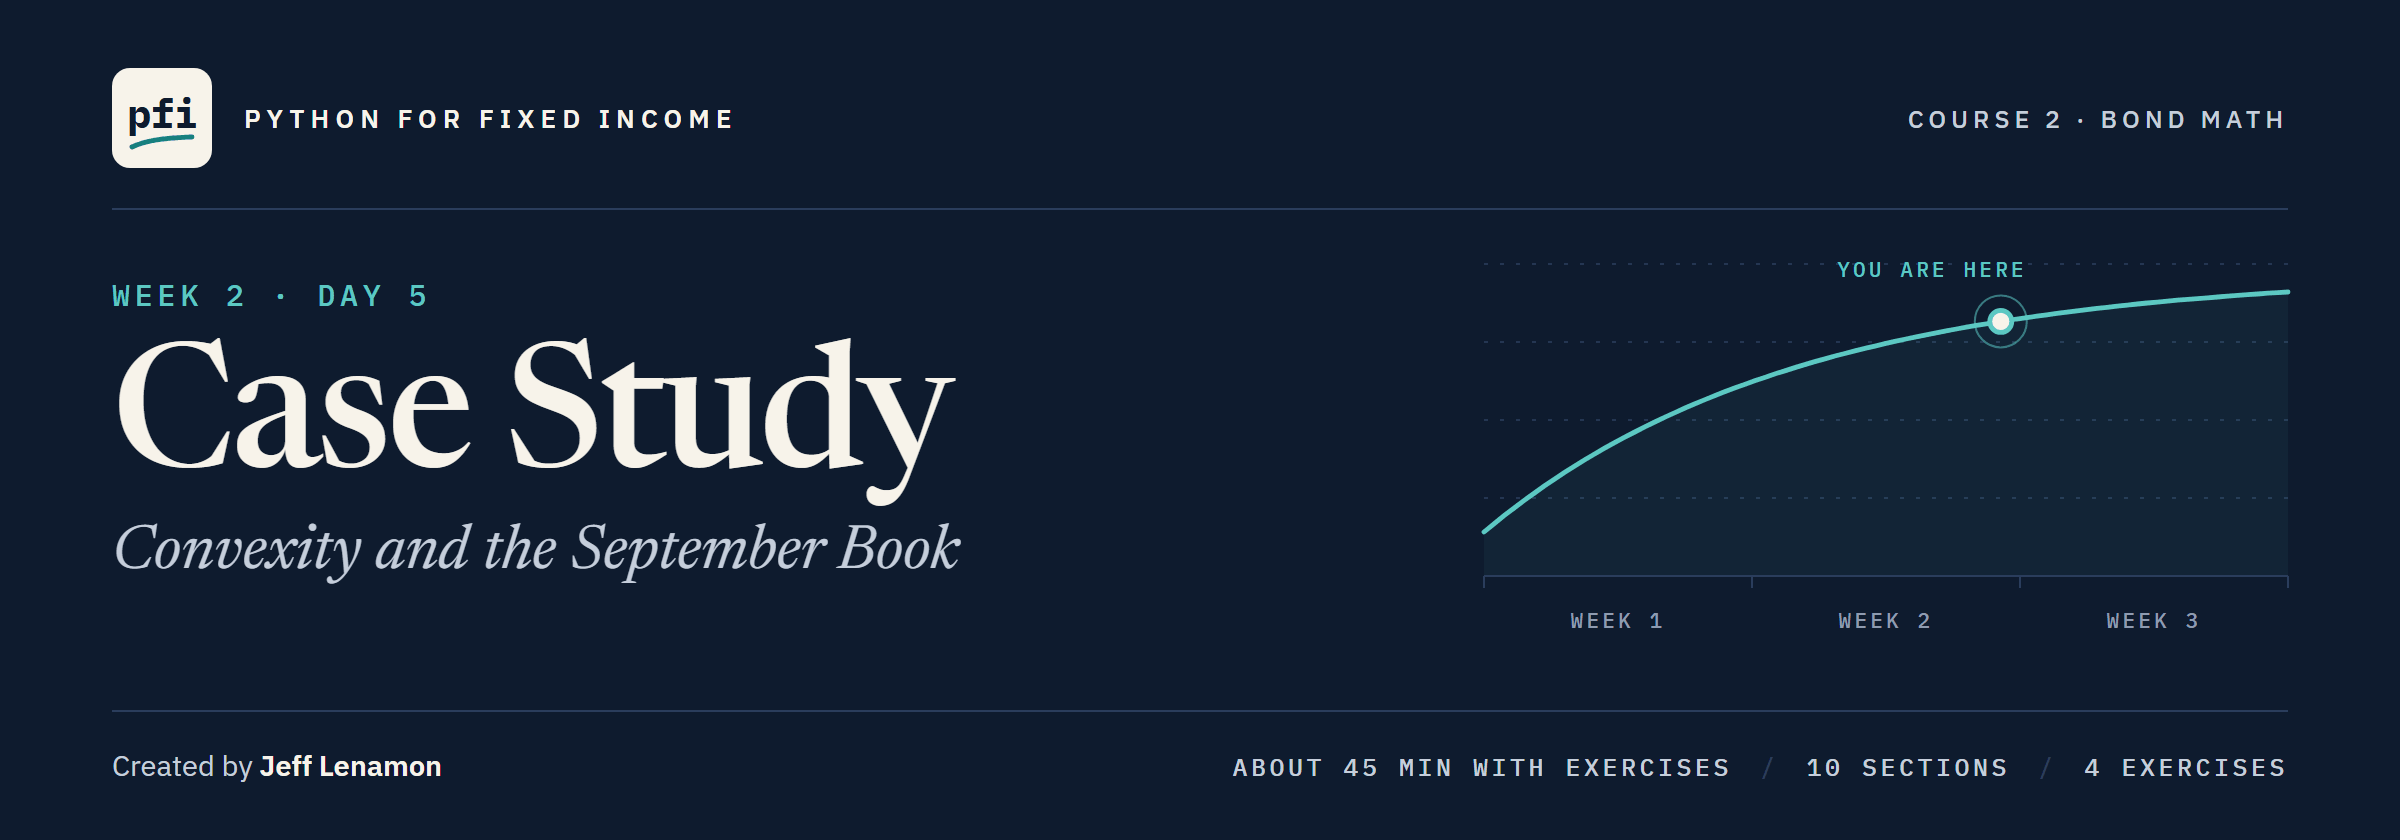

# Case Study: Convexity and the September Book

Week 2, Day 5. The bend duration's straight line leaves out, measured and tied to Excel, then a book of 200 bonds rebuilt with the week's module and added up in dollars per basis point.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day5/10_case_study_convexity_and_the_september_book.ipynb)

## Problem Definition

### Context

The desk lead's tenth note:

> Notebook 09 put our four positions at 6,154.97 dollars a basis point: a straight line. For a 100 basis point move, how far off is that line, and what measures the bend? Put that measure in `bondmath`, tied to Excel, which has no function for it. Then September's holdings: 200 bonds priced by someone else's program. Rebuild every bond's price, accrued, yield and duration before we use the file, and run the same checks on the benchmark it came from. Last, what does the book carry in dollars per basis point, and what is its duration? Describe the book: no view on any bond.

### Objective

You are the desk's analyst: answer the five asks with your own module, and tie every number to Excel or to the file.
Every check is an `assert`, so one bond that disagrees stops the notebook.

### The Data

Notebook 09's four positions, settling Monday 30 November 2026, typed in 10.1.
`holdings.csv`, the September book: 200 bonds as of 30 September 2026, made by a program, the course's data generator.

<table align="left">
<tr><th align="left">Column</th><th align="left">Meaning</th><th align="left">Used for</th></tr>
<tr><td align="left"><code>as_of_date</code></td><td align="left">2026-09-30 for every bond, also the settlement date</td><td align="left">input</td></tr>
<tr><td align="left"><code>coupon</code>, <code>maturity</code>, <code>yield_pct</code></td><td align="left">coupon and yield in percent, the maturity date</td><td align="left">input</td></tr>
<tr><td align="left"><code>price</code>, <code>accrued</code>, <code>duration</code></td><td align="left">clean price and accrued per 100, modified duration in years, 3 decimals</td><td align="left">checked</td></tr>
<tr><td align="left"><code>par_held</code>, <code>market_value</code></td><td align="left">face held and market value, in dollars</td><td align="left">the book's totals</td></tr>
</table>
<br clear="left">

Issuers and CUSIPs are invented; every statement describes the data.

### How We Will Work

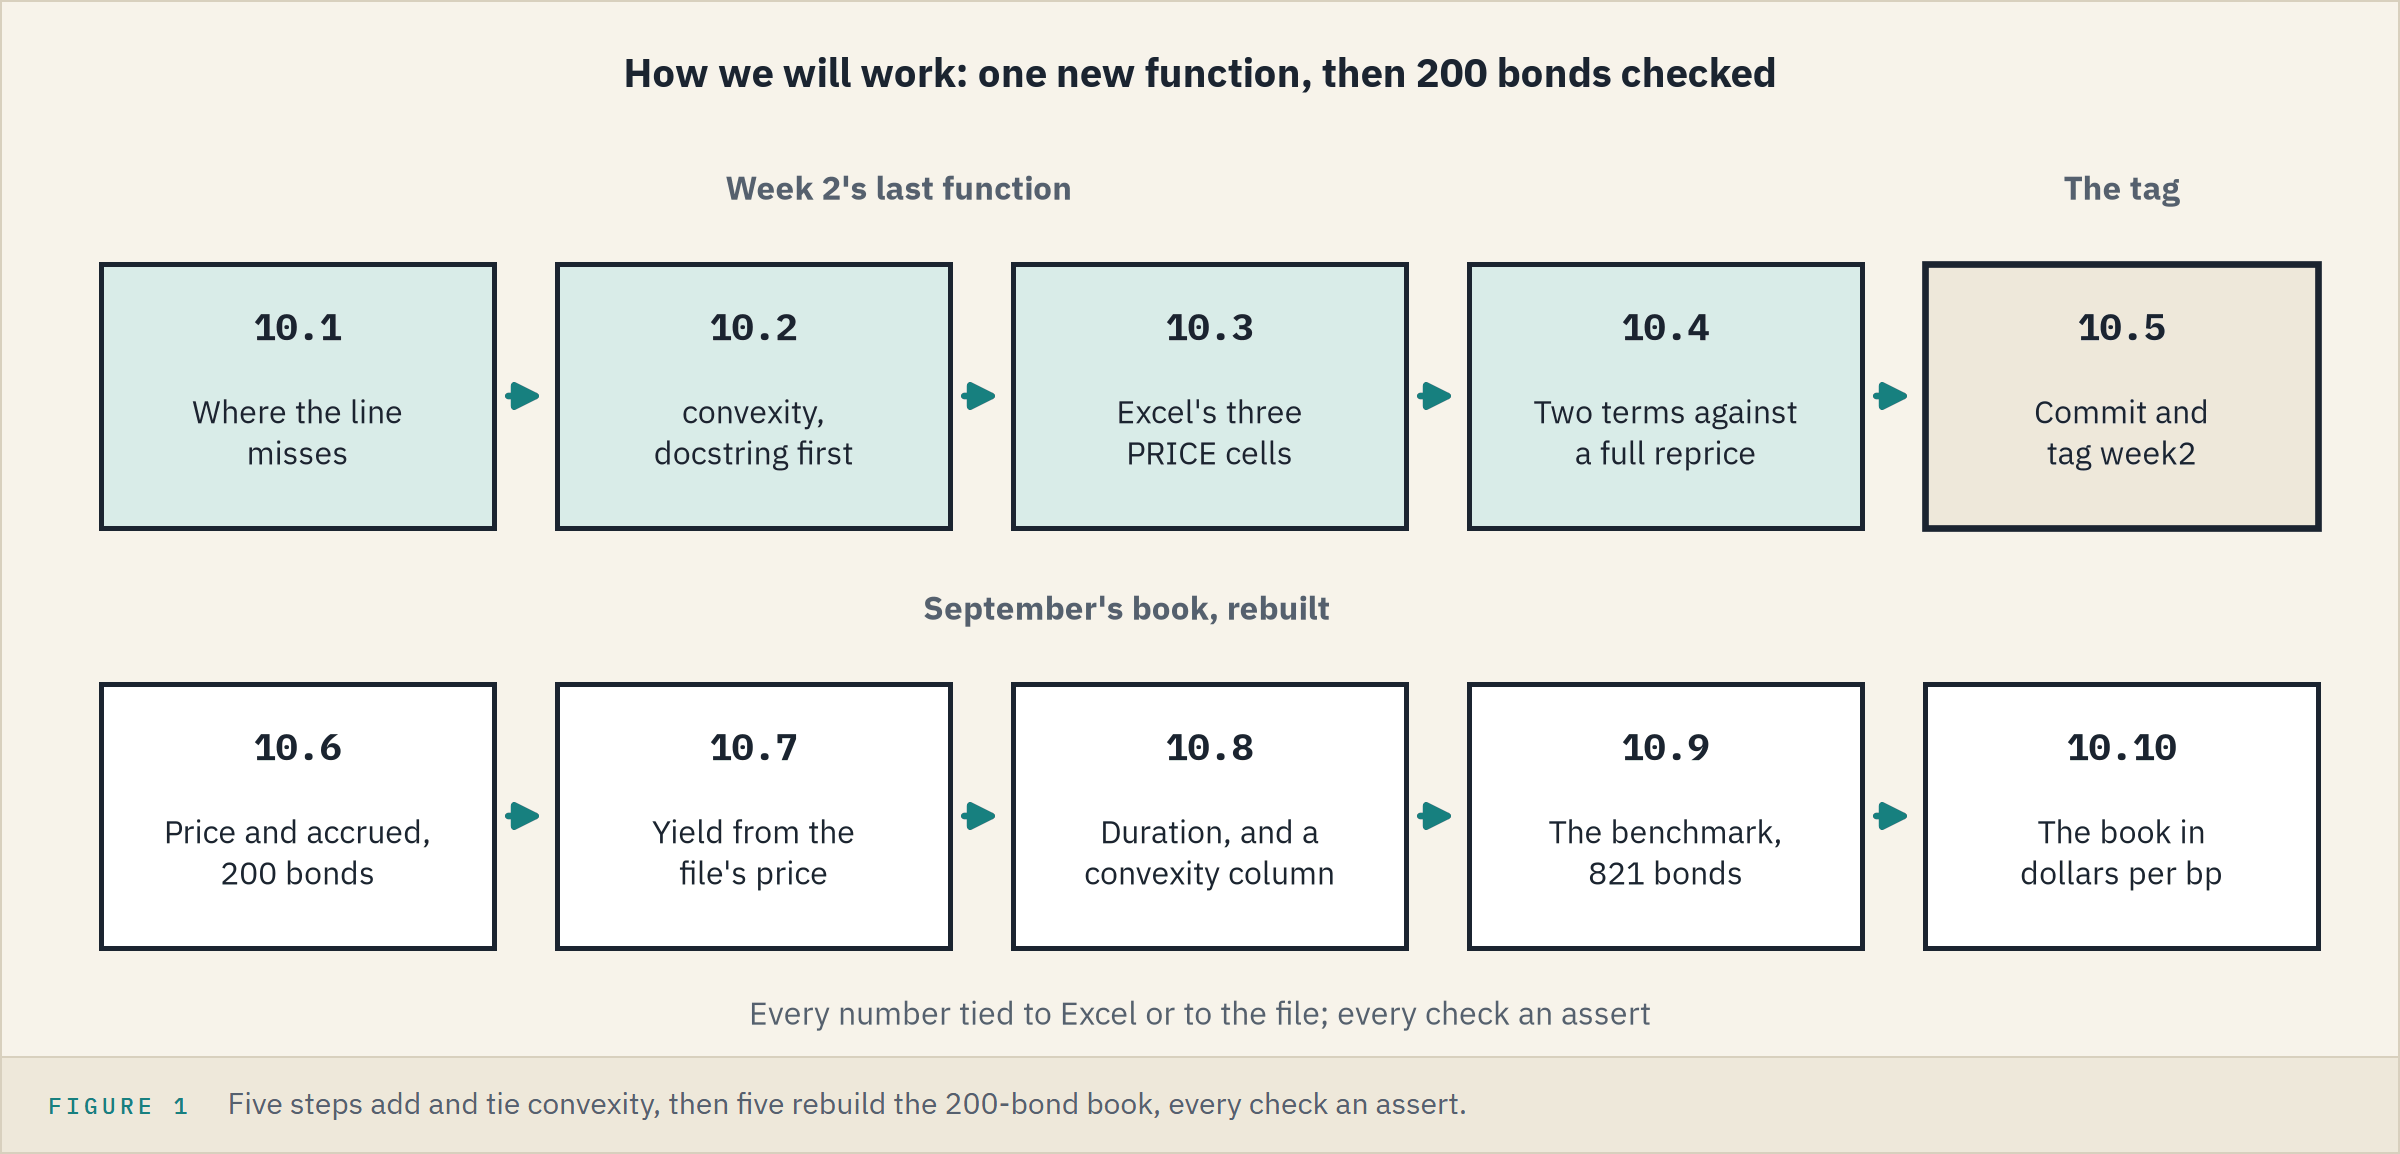

**One new function, then 200 bonds checked with every function of the week.**

## Your Route Through Day 5

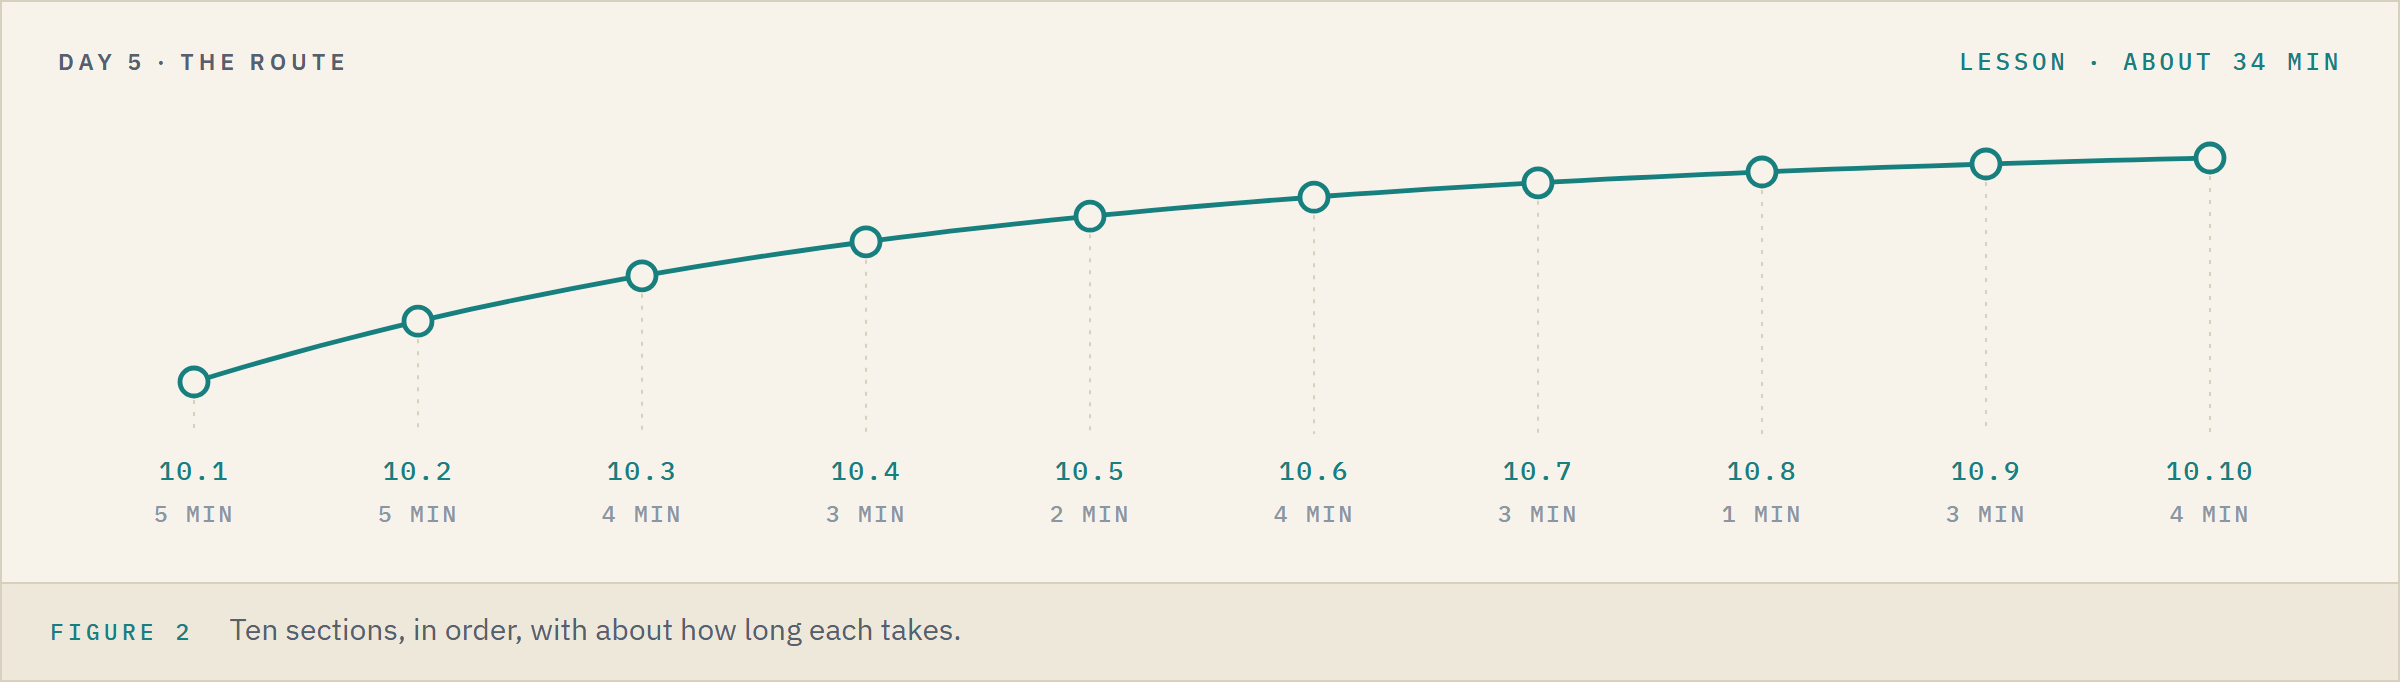

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">10.1</td><td align="left">Where Duration's Straight Line Misses</td><td align="left">5 min</td></tr>
<tr><td align="left">10.2</td><td align="left">Convexity and <code>convexity</code></td><td align="left">5 min</td></tr>
<tr><td align="left">10.3</td><td align="left">Checking It When Excel Has No Convexity Function</td><td align="left">4 min</td></tr>
<tr><td align="left">10.4</td><td align="left">Duration Plus Convexity Against a Full Reprice</td><td align="left">3 min</td></tr>
<tr><td align="left">10.5</td><td align="left">Tag the Week</td><td align="left">2 min</td></tr>
<tr><td align="left">10.6</td><td align="left">The Book's Price and Accrued</td><td align="left">4 min</td></tr>
<tr><td align="left">10.7</td><td align="left">Yield From the File's Price</td><td align="left">3 min</td></tr>
<tr><td align="left">10.8</td><td align="left">Duration, and Convexity as a New Column</td><td align="left">1 min</td></tr>
<tr><td align="left">10.9</td><td align="left">Two Systems Disagree, Again: the Benchmark</td><td align="left">3 min</td></tr>
<tr><td align="left">10.10</td><td align="left">The Book in Dollars per Basis Point</td><td align="left">4 min</td></tr>
</table>
<br clear="left">

**Time.** About 34 minutes for the lesson, then about 12 for the four exercises.

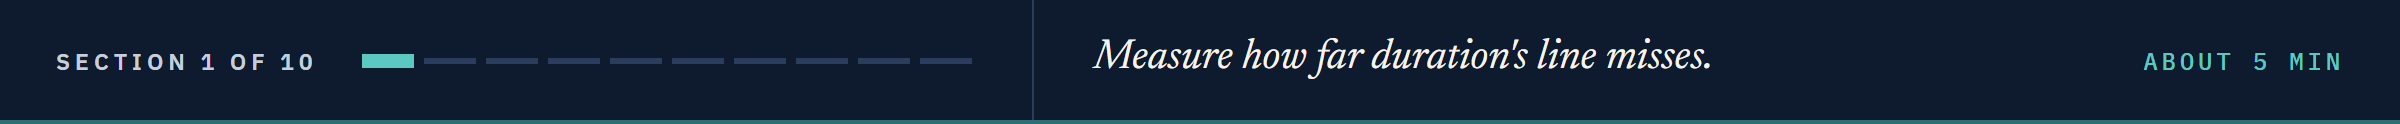

## 10.1 Where Duration's Straight Line Misses

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 09 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(10)

Work folder pfi_course2_10_k4w7q2xr: 4 data files, the module as notebook 09 left it, 9 commits, tagged week1


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........................                                              [100%]
27 passed in 0.50s



### Imports and the Four Positions

In [3]:
import importlib
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
import bondmath

In [4]:
# the four positions of notebook 09; par_held is the face held, in dollars
bonds = pd.DataFrame({
    'cusip': ['99001BZA7', '99002CZA4', '99003DZA1', '99004EZA8'],
    'issuer': ['Quorvane Energy', 'Dunmarrow Rail', 'Pellwick Paper', 'Halvering Foods'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'maturity': [date(2031, 9, 30), date(2033, 9, 30), date(2029, 9, 30), date(2036, 9, 30)],
    'yield_pct': [5.4, 6.125, 4.6, 7.7],
    'par_held': [5_000_000, 3_000_000, 4_000_000, 2_000_000],
})
settlement = date(2026, 11, 30)
maturities, coupons, yields = bonds['maturity'], bonds['coupon_pct'], bonds['yield_pct']

### Halvering, the Longest

Duration's estimate is a straight line in the yield:
change in dirty price = -modified duration x dy x dirty price, with dy the yield change as a decimal (100 bp is 0.01).

In [5]:
halvering_maturity = date(2036, 9, 30)
dirty_now = bondmath.dirty_price(settlement, halvering_maturity, 7.5, 7.7)
modified = bondmath.modified_duration(settlement, halvering_maturity, 7.5, 7.7)
print(f'Dirty price {dirty_now:.6f} per 100, modified duration {modified:.6f} years')
# duration's line for +100 bp: dy = 0.01
print(f'The line for +100 bp: {-modified * 0.01 * dirty_now:.4f} per 100')

Dirty price 99.872491 per 100, modified duration 6.759766 years
The line for +100 bp: -6.7511 per 100


### Predict 1: The Price After 100 bp

**Predict 1**

Q. Duration's line says Halvering loses 6.7511 per 100 if its yield rises 100 bp. The curve bends. What does the full reprice lose, per 100? Write down a number.

### Seven Yields, Two Answers

In [6]:
moves_bp = list(range(-300, 301, 100))
misses = pd.DataFrame({'move_bp': moves_bp})
# the full reprice: the bond at its yield plus the move (bp / 100 is percent)
misses['full'] = [bondmath.dirty_price(settlement, halvering_maturity, 7.5, 7.7 + bp / 100)
                  - dirty_now for bp in moves_bp]
# duration's line: dy is the move as a decimal, bp / 10000
misses['line'] = [-modified * bp / 10000 * dirty_now for bp in moves_bp]
misses['miss'] = misses['full'] - misses['line']
misses.round(4)

,move_bp,full,line,miss
0,-300,23.2141,20.2534,2.9607
1,-200,14.7737,13.5023,1.2714
2,-100,7.0585,6.7511,0.3073
3,0,0.0000,-0.0000,0.0000
4,100,-6.4633,-6.7511,0.2879
5,200,-12.3867,-13.5023,1.1156
6,300,-17.8202,-20.2534,2.4333


The full reprice loses 6.4633 per 100 at +100 bp, 0.2879 less than the line says.
Three times the move, about nine times the miss: 2.4333 at +300.
The miss is positive in every row: the price rises more than the line, and falls less.

### The Curve and Its Line

In [7]:
# 61 yields, 300 bp either side of 7.70 percent
yield_axis = np.linspace(4.7, 10.7, 61)
curve = [bondmath.dirty_price(settlement, halvering_maturity, 7.5, y) for y in yield_axis]
line = dirty_now - modified * (yield_axis - 7.7) / 100 * dirty_now

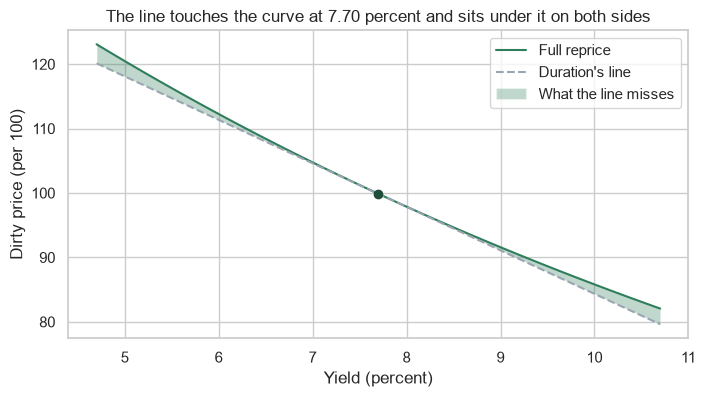

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(yield_axis, curve, label='Full reprice')
ax.plot(yield_axis, line, linestyle='--', label="Duration's line")
# fill_between shades the area between two lines drawn over the same x values
ax.fill_between(yield_axis, line, curve, alpha=0.3, label='What the line misses')
ax.plot(7.7, dirty_now, marker='o', color='#1E4D3A')
ax.set_title('The line touches the curve at 7.70 percent and sits under it on both sides')
ax.set_xlabel('Yield (percent)')
ax.set_ylabel('Dirty price (per 100)')
ax.legend()
plt.show()

**The line sits under the curve on both sides: 0.29 per 100 off at +100 bp, 2.43 at +300 and 2.96 at -300. The bend needs its own number.**

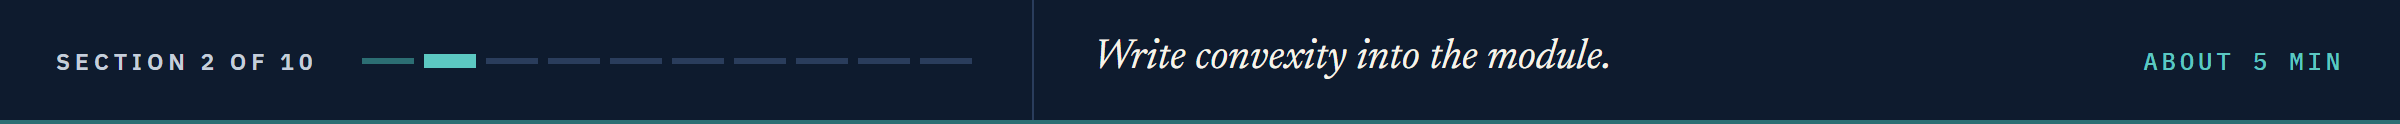

## 10.2 Convexity and `convexity`

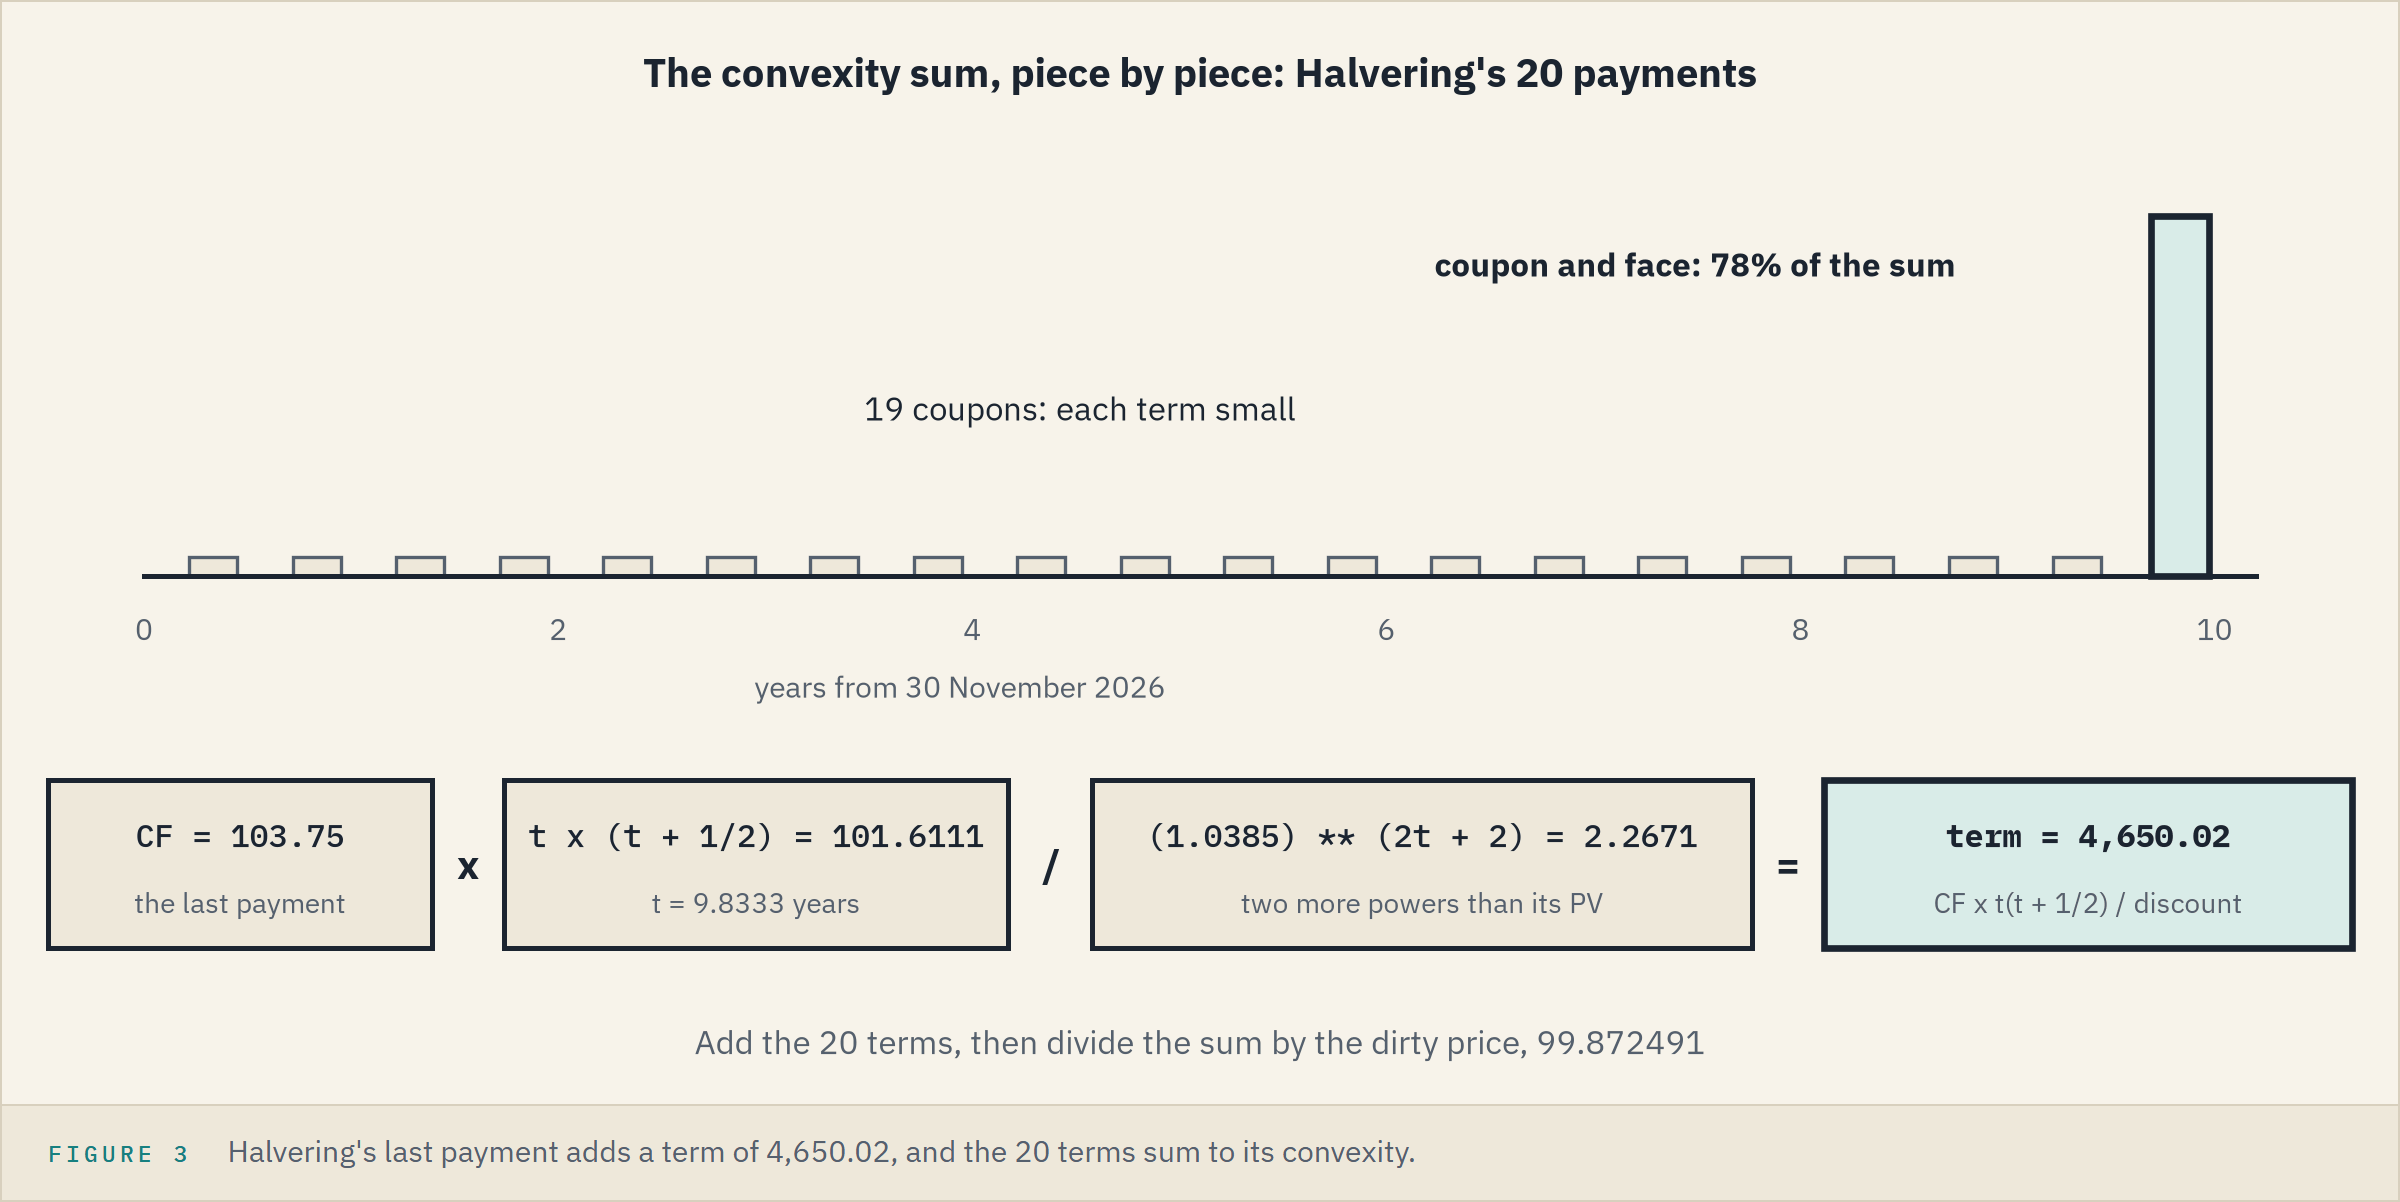

Duration is the slope of the price-yield curve over the price; **convexity** is how fast that slope changes, the curvature, also over the price.
It is a sum over the cash flows, with five pieces: each cash flow CF, its time t = (w + k) / f in years as in notebook 09, the frequency f, the yield y as a decimal, and the dirty price.

convexity = sum of CF x t x (t + 1/f) / (1 + y/f) ** (f x t + 2), divided by the dirty price

With it, the estimate gains a second term:

change in dirty price / dirty price = -modified duration x dy + 0.5 x convexity x dy ** 2

The second term is a square, positive whether yields rise or fall: the sign of 10.1's miss.
Time enters about squared, so before discounting, a payment twice as far away adds about four times as much.

### Append It, Docstring First

The docstring states the units (years squared, unscaled), the formula, the estimate it feeds, and Excel's three-cell check.
The loop is notebook 09's `macaulay_duration` with t x (t + 1/f) in place of t, and two more powers of (1 + y/f).

In [9]:
%%writefile -a bondmath.py


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv

Appending to bondmath.py


### Predict 2: Twice the Duration, How Much Convexity?

**Predict 2**

Q. Halvering's modified duration, 6.76 years, is 2.6 times Pellwick's 2.61. Its convexity is:

A) about 2.6 times Pellwick's
B) about 7 times
C) about 26 times

### Four Bonds

In [10]:
importlib.reload(bondmath)
bonds['modified'] = [bondmath.modified_duration(settlement, m, c, y)
                     for m, c, y in zip(maturities, coupons, yields)]
bonds['convexity'] = [bondmath.convexity(settlement, m, c, y)
                      for m, c, y in zip(maturities, coupons, yields)]
bonds[['issuer', 'modified', 'convexity']].round(4)

,issuer,modified,convexity
0,Quorvane Energy,4.1804,20.8885
1,Dunmarrow Rail,5.4623,36.3887
2,Pellwick Paper,2.6051,8.3305
3,Halvering Foods,6.7598,59.5474


B: Halvering's convexity, 59.5474 years squared, is 7.1 times Pellwick's 8.3305.
Every value is positive: a bullet bond's curve always bends this way.

### Duration Beside Convexity

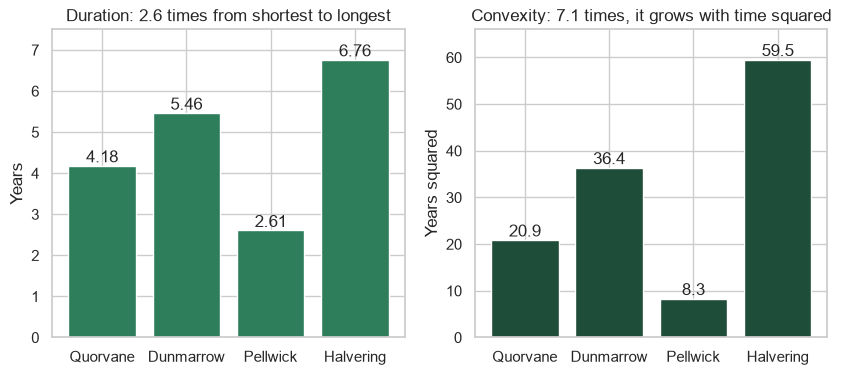

In [11]:
# the first word of each issuer, so the labels fit
names = bonds['issuer'].str.split().str[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar_label(axes[0].bar(names, bonds['modified']), fmt='%.2f')
axes[0].set_title('Duration: 2.6 times from shortest to longest')
axes[0].set_ylabel('Years')
# room above the tallest bar for its label
axes[0].set_ylim(0, 7.5)
axes[1].bar_label(axes[1].bar(names, bonds['convexity'], color='#1E4D3A'), fmt='%.1f')
axes[1].set_title('Convexity: 7.1 times, it grows with time squared')
axes[1].set_ylabel('Years squared')
axes[1].set_ylim(0, 66)
plt.show()

### Scaled Three Ways

In [12]:
# row 3 is Halvering
halvering_convexity = bonds.loc[3, 'convexity']
print(f'Unscaled {halvering_convexity:.4f}, divided by 100 {halvering_convexity / 100:.4f}, '
      f'halved {halvering_convexity / 2:.4f}')

Unscaled 59.5474, divided by 100 0.5955, halved 29.7737


Some sources divide convexity by 100; some halve it and drop the estimate's 0.5.
This course's is unscaled: ask which scaling any other number uses before comparing.

**Convexity grows with time squared: 8.33 years squared for Pellwick, 59.55 for Halvering, unscaled.**

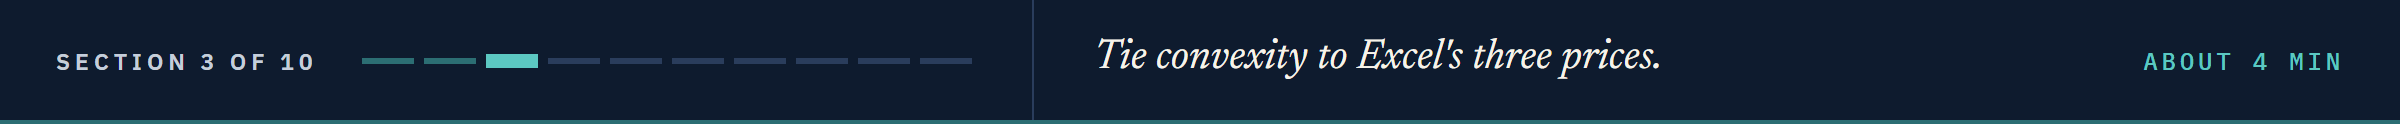

## 10.3 Checking It When Excel Has No Convexity Function

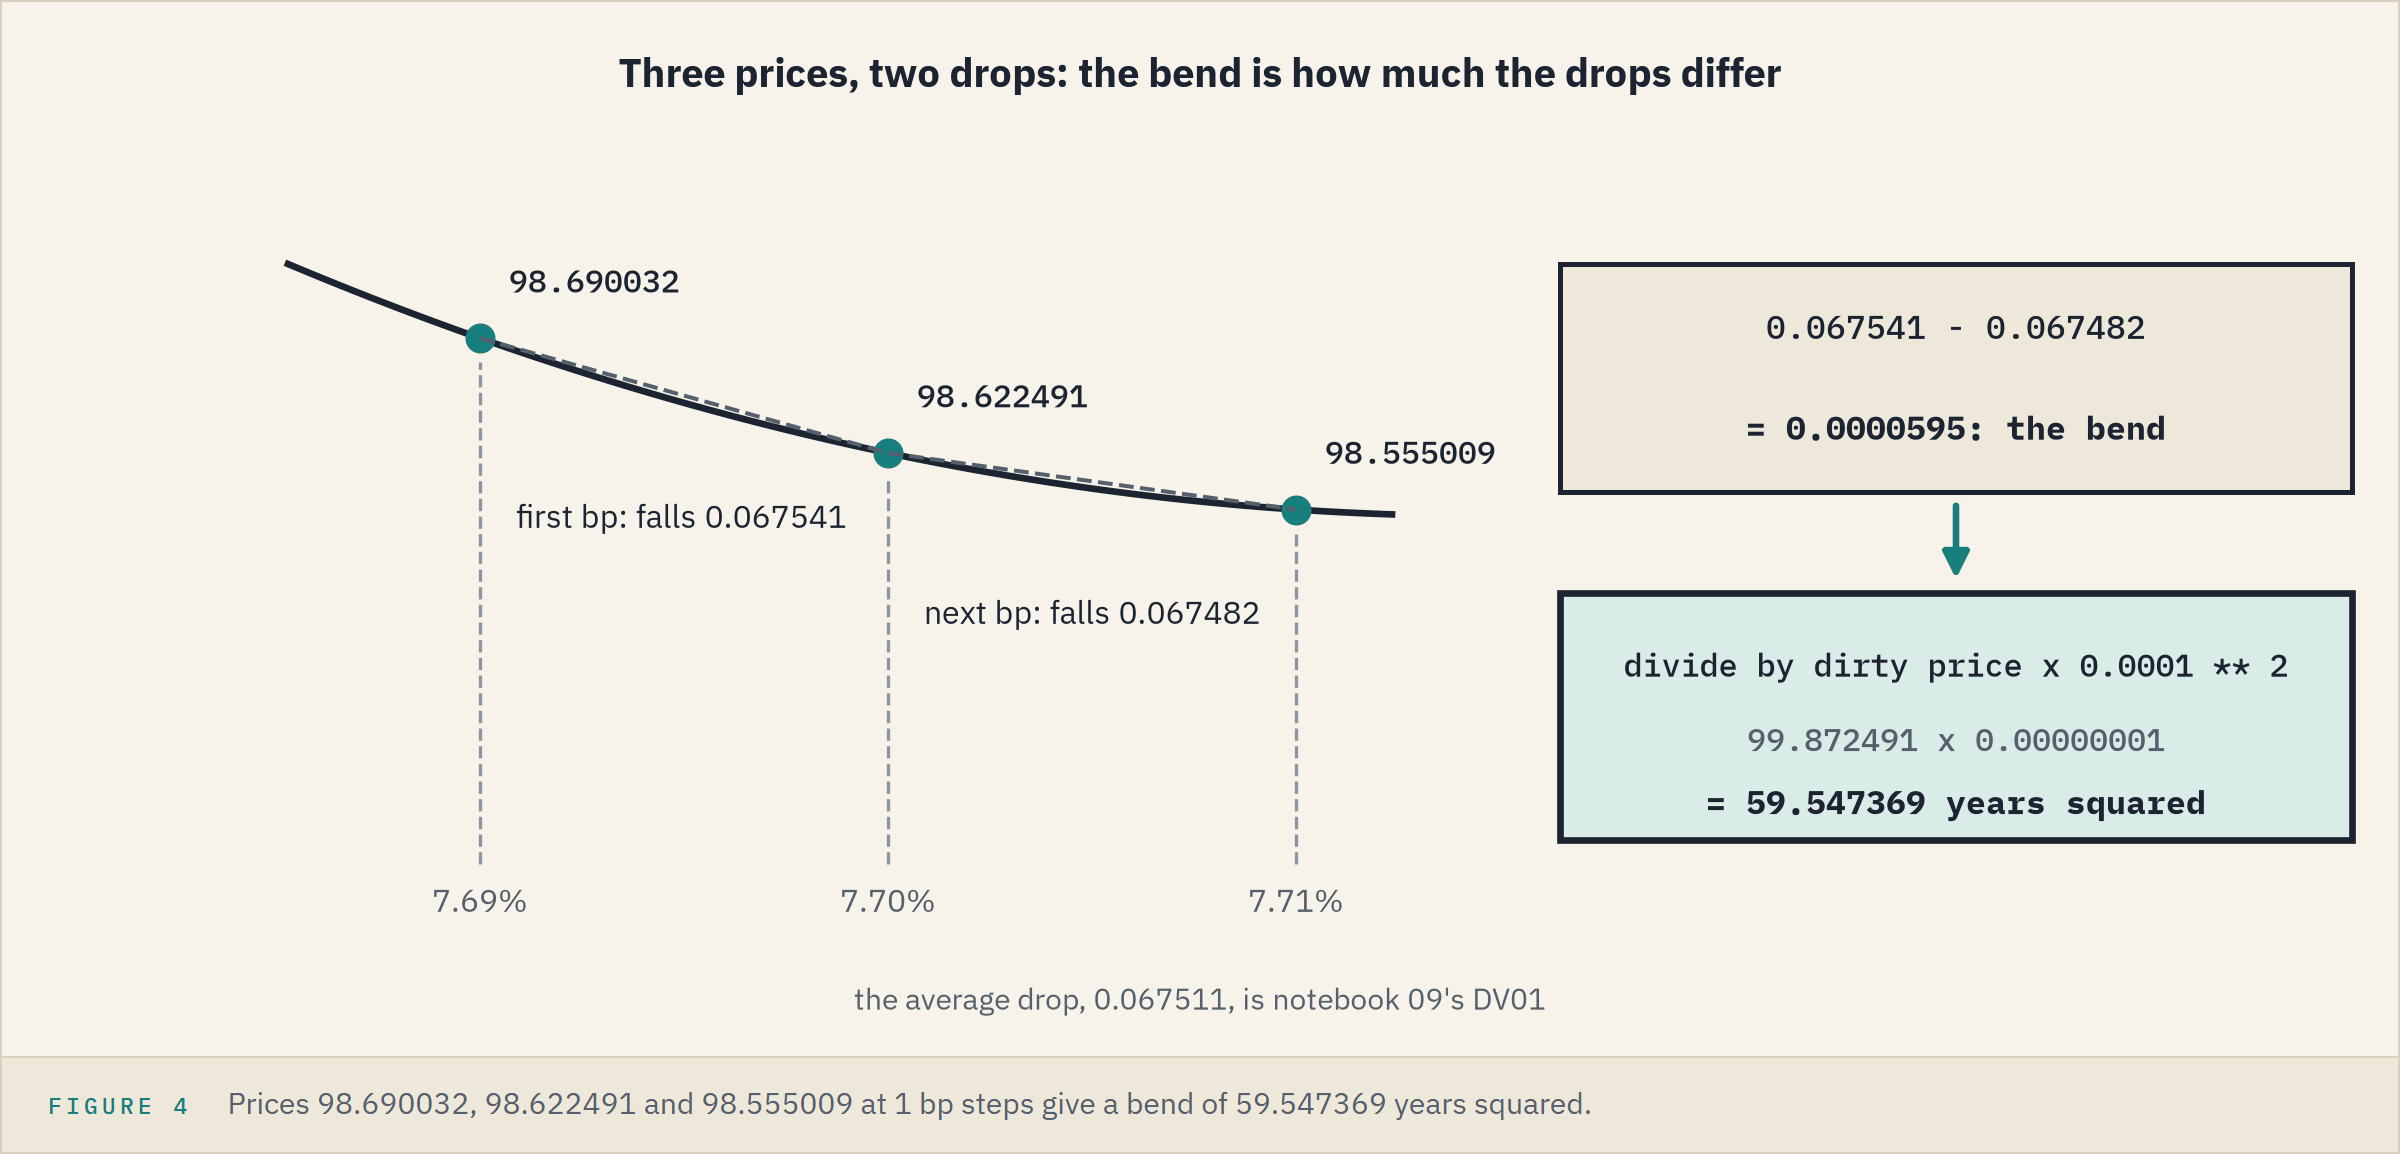

Excel has `DURATION` and `MDURATION`, but no convexity function.
So the check comes from the definition: notebook 09's bump took one slope from two prices; three prices 1 bp apart give two slopes, and the bend is how much they differ.

central difference = (P(y + h) + P(y - h) - 2 x P(y)) / (dirty price x h ** 2), with h = 0.0001, 1 bp as a decimal

Clean prices will do: accrued does not move with the yield, so it cancels.

### Three Prices in Python

In [13]:
h = 0.0001
# bondmath takes percent, so 1 bp is 0.01
p_mid = bondmath.price(settlement, halvering_maturity, 7.5, 7.7)
p_down = bondmath.price(settlement, halvering_maturity, 7.5, 7.7 - 0.01)
p_up = bondmath.price(settlement, halvering_maturity, 7.5, 7.7 + 0.01)
central = (p_up + p_down - 2 * p_mid) / (dirty_now * h ** 2)
print(f'Central difference {central:.6f}, convexity {halvering_convexity:.6f}')
print(f'Gap {abs(central - halvering_convexity):.1e}')

Central difference 59.547369, convexity 59.547364
Gap 4.8e-06


It measures the average curvature across the 2 bp step, not at one point, so the tolerance is 1e-3.

### Four Bonds Against Excel's Three Cells

In [14]:
reference = pd.read_csv('bondmath_excel_reference.csv')
week2 = reference[reference['group'] == 'week2'].set_index('case_id')
# convexity_fd: Excel's central difference from three PRICE cells
bonds['excel'] = week2.loc[bonds['cusip'], 'convexity_fd'].to_numpy()
bonds['gap'] = (bonds['convexity'] - bonds['excel']).abs()
assert bonds['gap'].max() < 1e-3
formats = {'convexity': '{:.6f}', 'excel': '{:.6f}', 'gap': '{:.1e}'}
bonds[['issuer', 'convexity', 'excel', 'gap']].style.format(formats)

,issuer,convexity,excel,gap
0,Quorvane Energy,20.888538,20.888538,4.5e-07
1,Dunmarrow Rail,36.388736,36.388738,1.5e-06
2,Pellwick Paper,8.330536,8.330536,1.3e-08
3,Halvering Foods,59.547364,59.547369,4.8e-06


**Excel side by side.** Halvering in a blank sheet.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Clean price, A1</td><td align="left"><code>p_mid</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2036,9,30),7.5/100,7.7/100,100,2,0)</code></td><td align="left">98.622491</td></tr>
<tr><td align="left">1 bp lower, A2</td><td align="left"><code>p_down</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2036,9,30),7.5/100,7.7/100-0.0001,100,2,0)</code></td><td align="left">98.690032</td></tr>
<tr><td align="left">1 bp higher, A3</td><td align="left"><code>p_up</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2036,9,30),7.5/100,7.7/100+0.0001,100,2,0)</code></td><td align="left">98.555009</td></tr>
<tr><td align="left">Accrued, A4</td><td align="left"><code>bondmath.accrued_interest(settlement, halvering_maturity, 7.5)</code></td><td align="left"><code>=100*7.5/100/2*COUPDAYBS(DATE(2026,11,30),DATE(2036,9,30),2,0)/COUPDAYS(DATE(2026,11,30),DATE(2036,9,30),2,0)</code></td><td align="left">1.25</td></tr>
<tr><td align="left">Central difference, A5</td><td align="left"><code>central</code></td><td align="left"><code>=(A2+A3-2*A1)/((A1+A4)*0.0001^2)</code></td><td align="left">59.54736851639378</td></tr>
</table>
<br clear="left">

A5 is the `convexity_fd` value in the reference file.

### The Test

The test holds `convexity` to `convexity_fd` on every reference row outside the final coupon period, where `PRICE` is simple interest (notebook 08's 8.5).
The comprehension's `if` keeps those rows, as in notebook 09's bump test.
The file's 200 holdings rows are among them, so the test also ties `convexity` to today's book.

In [15]:
%%writefile -a test_bondmath.py


def test_convexity_matches_excel_finite_difference():
    # the final period is simple interest, so Excel's curvature there is another formula's
    rows = [row for row in REFERENCE if row["coupnum"] != "1"]
    for row in rows:
        # Excel: (PRICE(y+h) + PRICE(y-h) - 2 PRICE(y)) / ((PRICE(y) + accrued) h^2), with h = 1 bp
        result = bondmath.convexity(*bond_inputs(row))
        assert result == pytest.approx(float(row["convexity_fd"]), abs=1e-3), row["case_id"]

Appending to test_bondmath.py


### Run pytest

In [16]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

............................                                             [100%]
28 passed in 0.50s



**`convexity` matches Excel's three `PRICE` cells on all 294 rows outside the final period.**

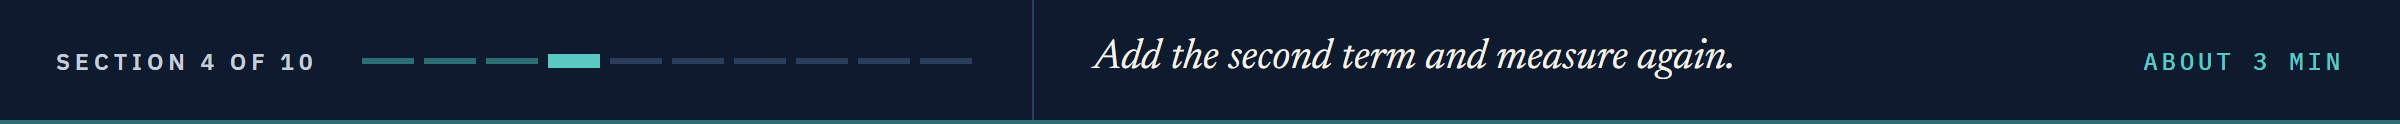

## 10.4 Duration Plus Convexity Against a Full Reprice

### The Seven Yields Again

In [17]:
# the second term: half the convexity times dy squared, as a share of the dirty price
misses['both'] = [(-modified * bp / 10000 + 0.5 * halvering_convexity * (bp / 10000) ** 2)
                  * dirty_now for bp in moves_bp]
misses['miss_both'] = misses['full'] - misses['both']
misses.round(4)

,move_bp,full,line,miss,both,miss_both
0,-300,23.2141,20.2534,2.9607,22.9297,0.2845
1,-200,14.7737,13.5023,1.2714,14.6917,0.0820
2,-100,7.0585,6.7511,0.3073,7.0485,0.0100
3,0,0.0000,-0.0000,0.0000,0.0000,0.0000
4,100,-6.4633,-6.7511,0.2879,-6.4538,-0.0095
5,200,-12.3867,-13.5023,1.1156,-12.3129,-0.0738
6,300,-17.8202,-20.2534,2.4333,-17.5772,-0.2430


At +100 bp the miss falls from 0.2879 to -0.0095 per 100, and at -100 bp from 0.3073 to 0.0100.
The convexity term adds 0.2977 percent of the price at 100 bp and 2.6796 at 300.
Two terms describe a curve well, not perfectly: the full reprice is the answer.

### Curve, Line, and Parabola

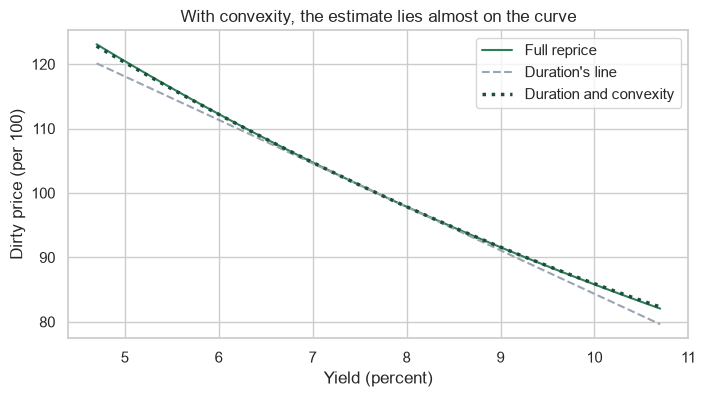

In [18]:
# the estimate is a parabola in the yield: dy as a decimal at every point of the axis
dy_axis = (yield_axis - 7.7) / 100
parabola = dirty_now * (1 - modified * dy_axis + 0.5 * halvering_convexity * dy_axis ** 2)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(yield_axis, curve, label='Full reprice')
ax.plot(yield_axis, line, linestyle='--', label="Duration's line")
ax.plot(yield_axis, parabola, linestyle=':', linewidth=2.5, label='Duration and convexity')
ax.set_title('With convexity, the estimate lies almost on the curve')
ax.set_xlabel('Yield (percent)')
ax.set_ylabel('Dirty price (per 100)')
ax.legend()
plt.show()

### Four Bonds at +100 bp

In [19]:
bonds['dirty'] = [bondmath.dirty_price(settlement, m, c, y)
                  for m, c, y in zip(maturities, coupons, yields)]
bonds['dirty_up'] = [bondmath.dirty_price(settlement, m, c, y + 1)
                     for m, c, y in zip(maturities, coupons, yields)]
# both in percent of the dirty price, for dy = 0.01
bonds['estimate_pct'] = (-bonds['modified'] * 0.01 + 0.5 * bonds['convexity'] * 0.01 ** 2) * 100
bonds['full_pct'] = (bonds['dirty_up'] / bonds['dirty'] - 1) * 100
bonds['miss_pct'] = bonds['full_pct'] - bonds['estimate_pct']
bonds[['issuer', 'estimate_pct', 'full_pct', 'miss_pct']].round(6)

,issuer,estimate_pct,full_pct,miss_pct
0,Quorvane Energy,-4.075935,-4.077845,-0.001910
1,Dunmarrow Rail,-5.280391,-5.284763,-0.004372
2,Pellwick Paper,-2.563475,-2.563985,-0.000510
3,Halvering Foods,-6.462029,-6.471508,-0.009478


**Excel side by side.** The same sheet, A1 to A5 from 10.3.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Estimate for +100 bp, percent, A6</td><td align="left"><code>bonds['estimate_pct']</code></td><td align="left"><code>=(-MDURATION(DATE(2026,11,30),DATE(2036,9,30),7.5/100,7.7/100,2,0)*0.01+0.5*A5*0.01^2)*100</code></td><td align="left">-6.462029</td></tr>
<tr><td align="left">Full reprice for +100 bp, percent, A8</td><td align="left"><code>bonds['full_pct']</code></td><td align="left"><code>=(PRICE(DATE(2026,11,30),DATE(2036,9,30),7.5/100,7.7/100+0.01,100,2,0)-A1)/(A1+A4)*100</code></td><td align="left">-6.471508</td></tr>
</table>
<br clear="left">

For a 100 bp fall, `+MDURATION` and `-0.01` give 7.057503 and 7.067493.
A6 uses Excel's central difference; at six decimals nothing changes.

**Two terms close the miss from 0.29 to 0.01 per 100 at 100 bp: the note's first two asks.**

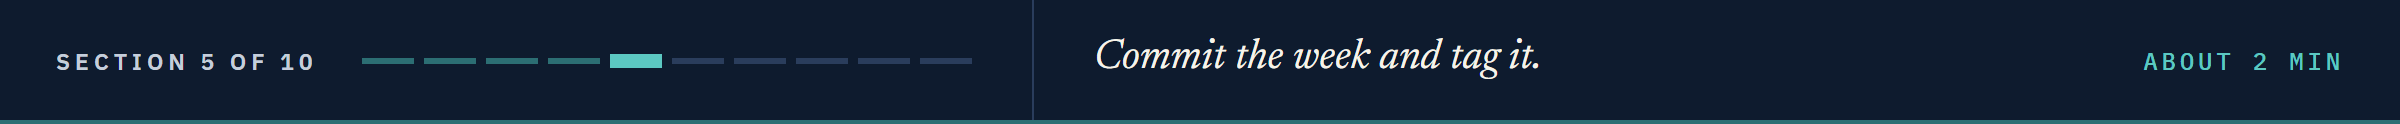

## 10.5 Tag the Week

`convexity` is week 2's last function: commit it, and name the commit that ends the week.

### Read the Diff, Commit

In [20]:
!git -C "{work}" status --short
!git -C "{work}" diff --stat
subject = 'Add convexity, checked against a central difference on Excel PRICE'
body = "Duration's straight line misses the bend in the price-yield curve; convexity measures it."
!git -C "{work}" add bondmath.py test_bondmath.py
!git -C "{work}" commit -q -m "{subject}" -m "{body}"

 M bondmath.py
 M test_bondmath.py
 bondmath.py      | 30 ++++++++++++++++++++++++++++++
 test_bondmath.py |  9 +++++++++
 2 files changed, 39 insertions(+)


### Name the Week

In [21]:
# the tag names today's commit, as week1 names notebook 05's
!git -C "{work}" tag week2
!git -C "{work}" log --oneline --decorate

646a02a (HEAD -> main, tag: week2) Add convexity, checked against a central difference on Excel PRICE
5fcb7c6 Notebook 09: macaulay_duration, modified_duration, and dv01
20b3546 Notebook 08: price, dirty_price, and yield_to_maturity
98124d3 Notebook 07: days_30_360, coupon_period_days, and accrued_interest
9fe8f04 Notebook 06: add_months, coupon_dates, and a .gitignore
322960d (tag: week1) Notebook 05: tests of par pricing and of price against yield
7147a11 Notebook 04: yield_from_price
3f57cac Notebook 03: convert_yield
408a678 Notebook 02: cash_flows and price_from_yield
d029474 Notebook 01: future_value and present_value


### Predict 3: What Lies Between Two Tags?

**Predict 3**

Q. Today's commit added 30 and 9 lines; `week1` is five commits back. `git diff --stat week1 week2` shows:

A) every line added since `week1`, notebooks 06 to 10
B) only today's 30 and 9
C) nothing, since a tag is only a name

### Compare the Tags, and the Commits Between

In [22]:
!git -C "{work}" diff --stat week1 week2
# week1..week2: the commits after week1, up to and including week2
!git -C "{work}" log --oneline week1..week2

 .gitignore       |   3 +
 bondmath.py      | 308 +++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_bondmath.py | 158 ++++++++++++++++++++++++++++
 3 files changed, 469 insertions(+)
646a02a Add convexity, checked against a central difference on Excel PRICE
5fcb7c6 Notebook 09: macaulay_duration, modified_duration, and dv01
20b3546 Notebook 08: price, dirty_price, and yield_to_maturity
98124d3 Notebook 07: days_30_360, coupon_period_days, and accrued_interest
9fe8f04 Notebook 06: add_months, coupon_dates, and a .gitignore


A: a diff between two names compares the two commits they name, whatever lies between.

**`week1` and `week2` name the module at the end of each week: 308 lines of `bondmath.py`, 158 of tests, and notebook 06's `.gitignore` lie between them. The module is done; now the file.**

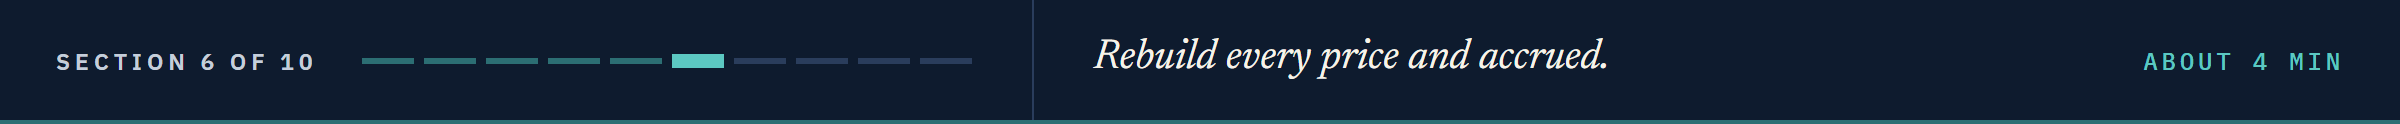

## 10.6 The Book's Price and Accrued

September's holdings were priced by someone else's program and rounded to 3 decimals: rebuild each number before trusting it.

### Read and Check the Shape

In [23]:
book = pd.read_csv('holdings.csv')
# bondmath takes dates: .dt.date after pd.to_datetime, as in notebook 08
book['settle'] = pd.to_datetime(book['as_of_date']).dt.date
book['maturity_date'] = pd.to_datetime(book['maturity']).dt.date
assert len(book) == 200 and book['cusip'].is_unique
assert book['as_of_date'].nunique() == 1 and (book['maturity_date'] > book['settle']).all()
print(len(book), 'bonds as of', book['settle'].iloc[0])

200 bonds as of 2026-09-30


### Two Tolerances, Written Once

A column rounded to 3 decimals can sit up to 0.0005 from the exact number.
A yield solved from a rounded price carries that rounding with it.

In [24]:
# capital letters: numbers set once and never changed
# half of 0.001, plus a hair for floating point
ROUNDED_3 = 0.0005 + 1e-9
# a yield solved from a price rounded to 3 decimals, in percent
YIELD_FROM_ROUNDED_PRICE = 0.001

### Price and Accrued for 200 Bonds

In [25]:
inputs = list(zip(book['settle'], book['maturity_date'], book['coupon'], book['yield_pct']))
book['price_calc'] = [bondmath.price(*bond) for bond in inputs]
book['accrued_calc'] = [bondmath.accrued_interest(s, m, c) for s, m, c, y in inputs]
price_gap = (book['price_calc'] - book['price']).abs()
accrued_gap = (book['accrued_calc'] - book['accrued']).abs()
assert price_gap.max() <= ROUNDED_3 and accrued_gap.max() <= ROUNDED_3
print(f'Largest price gap {price_gap.max():.7f}, largest accrued gap {accrued_gap.max()}')

Largest price gap 0.0004985, largest accrued gap 0.0005000000000000004


Both pass on all 200 bonds, but the accrued gap sits a hair above 0.0005.

### The Widest Gap

In [26]:
widest = accrued_gap.idxmax()
book.loc[widest, ['cusip', 'coupon', 'accrued_calc', 'accrued']]

cusip           99113JAA2
coupon               5.25
accrued_calc       0.0875
accrued             0.087
Name: 158, dtype: object

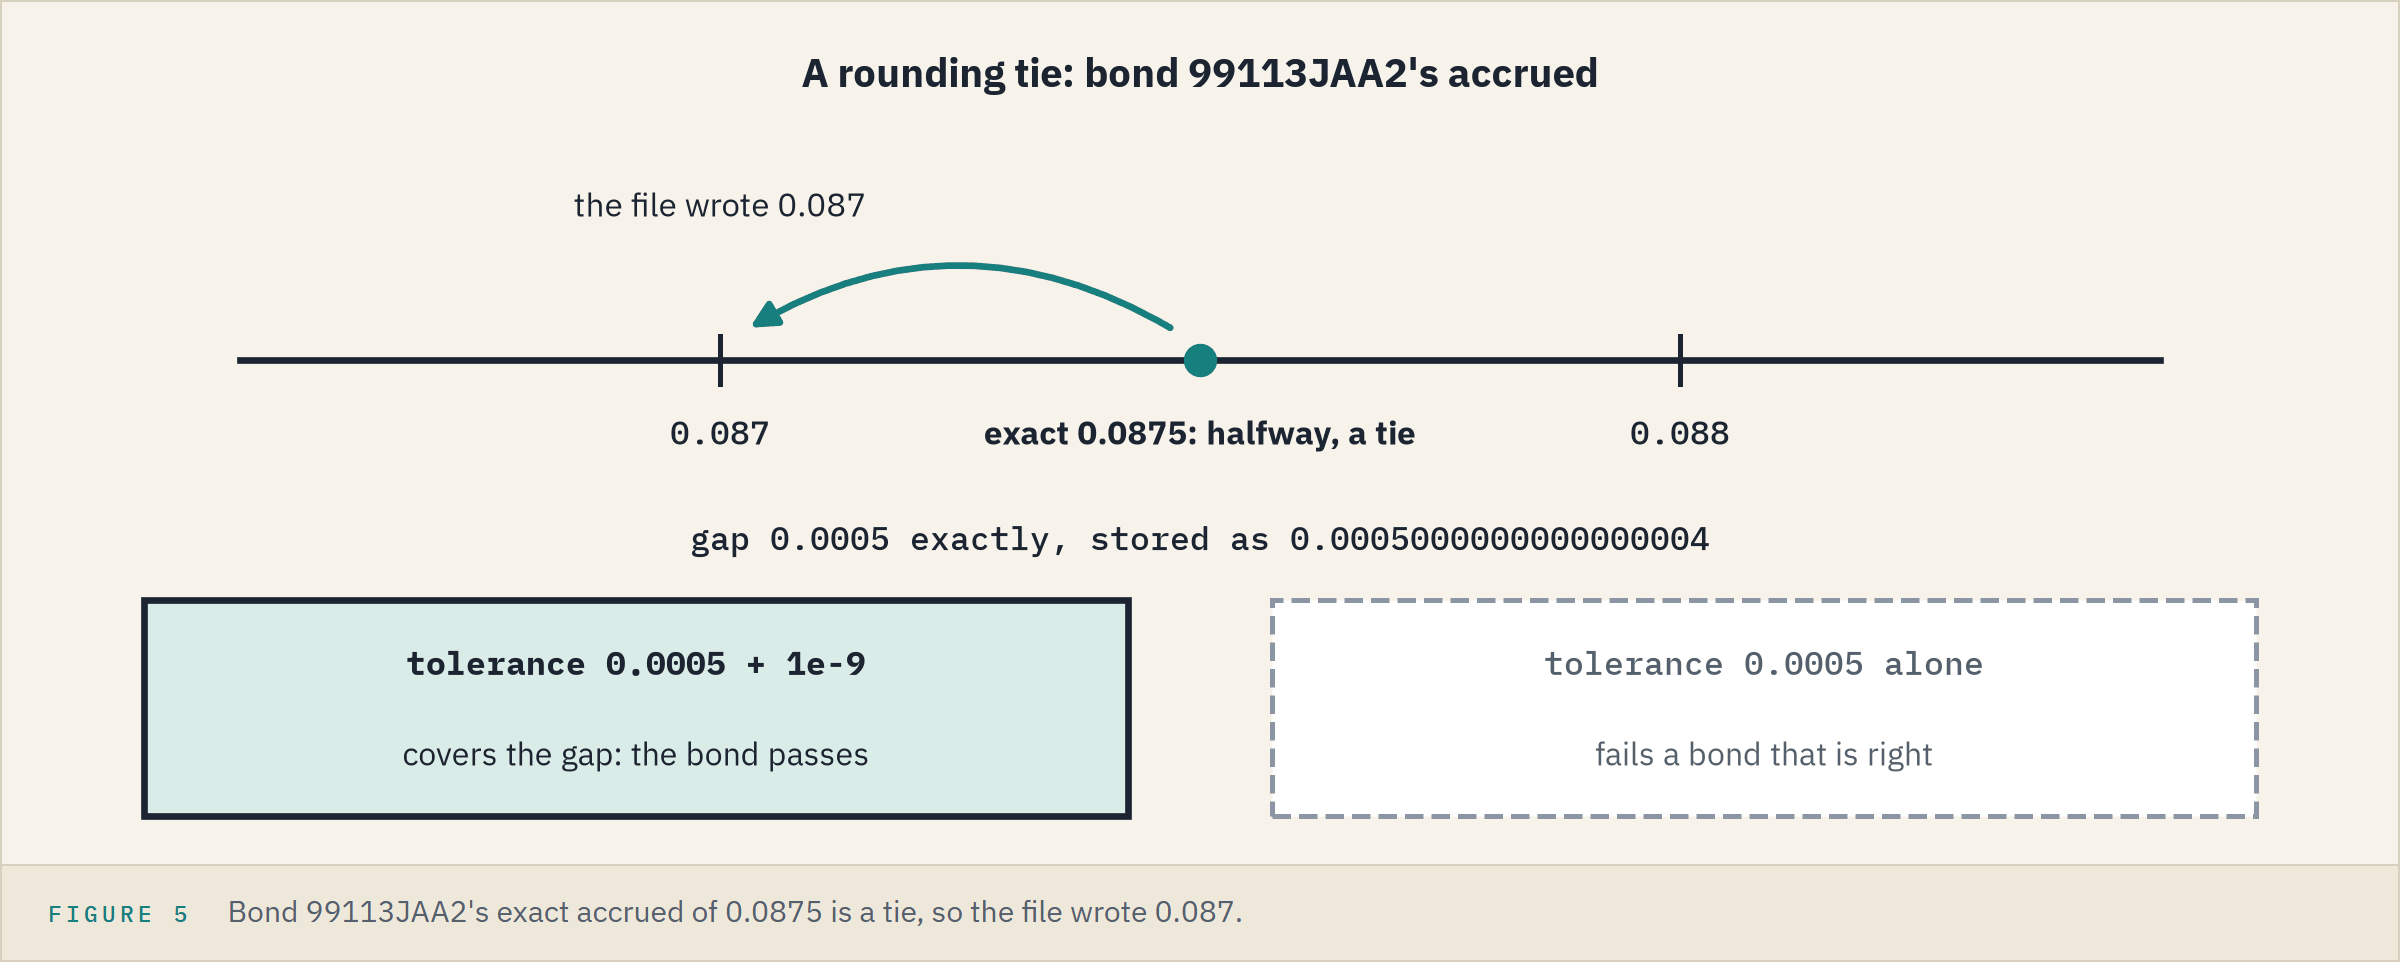

The exact accrued ends in a 5 at the fourth decimal; the file rounded it down.
Floating point stores neither number exactly, so the gap of exactly 0.0005 comes out a hair above it.

**Price and accrued tie on all 200 bonds; the one gap a hair above 0.0005 is a rounding tie.**

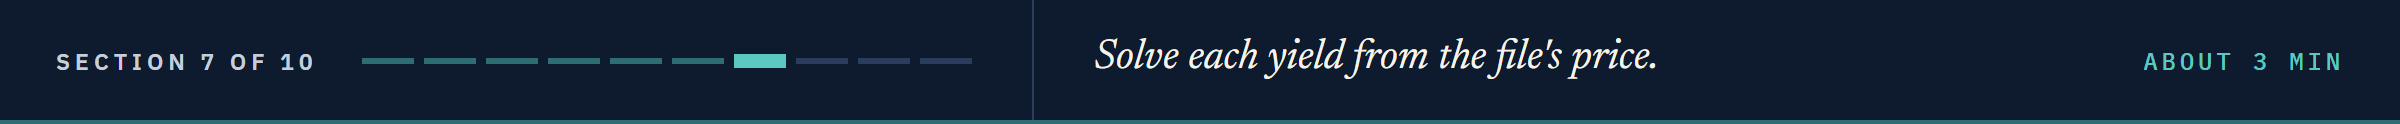

## 10.7 Yield From the File's Price

Now the other way: solve each yield from the file's rounded price with notebook 08's `yield_to_maturity`.

### Predict 4: Where the Yield Misses Most

**Predict 4**

Q. Every price in the file carries up to 0.0005 of rounding. Solved back into a yield, which bonds miss the file's yield most?

A) the longest
B) no pattern
C) the shortest

### Solve 200 Yields

In [27]:
book['yield_calc'] = [bondmath.yield_to_maturity(s, m, c, p) for s, m, c, p
                      in zip(book['settle'], book['maturity_date'], book['coupon'], book['price'])]
book['duration_calc'] = [bondmath.modified_duration(*bond) for bond in inputs]
book['yield_gap'] = (book['yield_calc'] - book['yield_pct']).abs()
assert book['yield_gap'].max() <= YIELD_FROM_ROUNDED_PRICE
book.nlargest(5, 'yield_gap')[['cusip', 'duration_calc', 'price', 'yield_gap']].round(6)

,cusip,duration_calc,price,yield_gap
177,99006GAC4,0.927120,101.347,0.000440
112,99026AAD1,1.004956,100.230,0.000433
125,99003DAG5,1.016945,100.459,0.000424
188,99111HAA8,1.192764,101.036,0.000346
71,99088KAA0,1.310381,98.352,0.000318


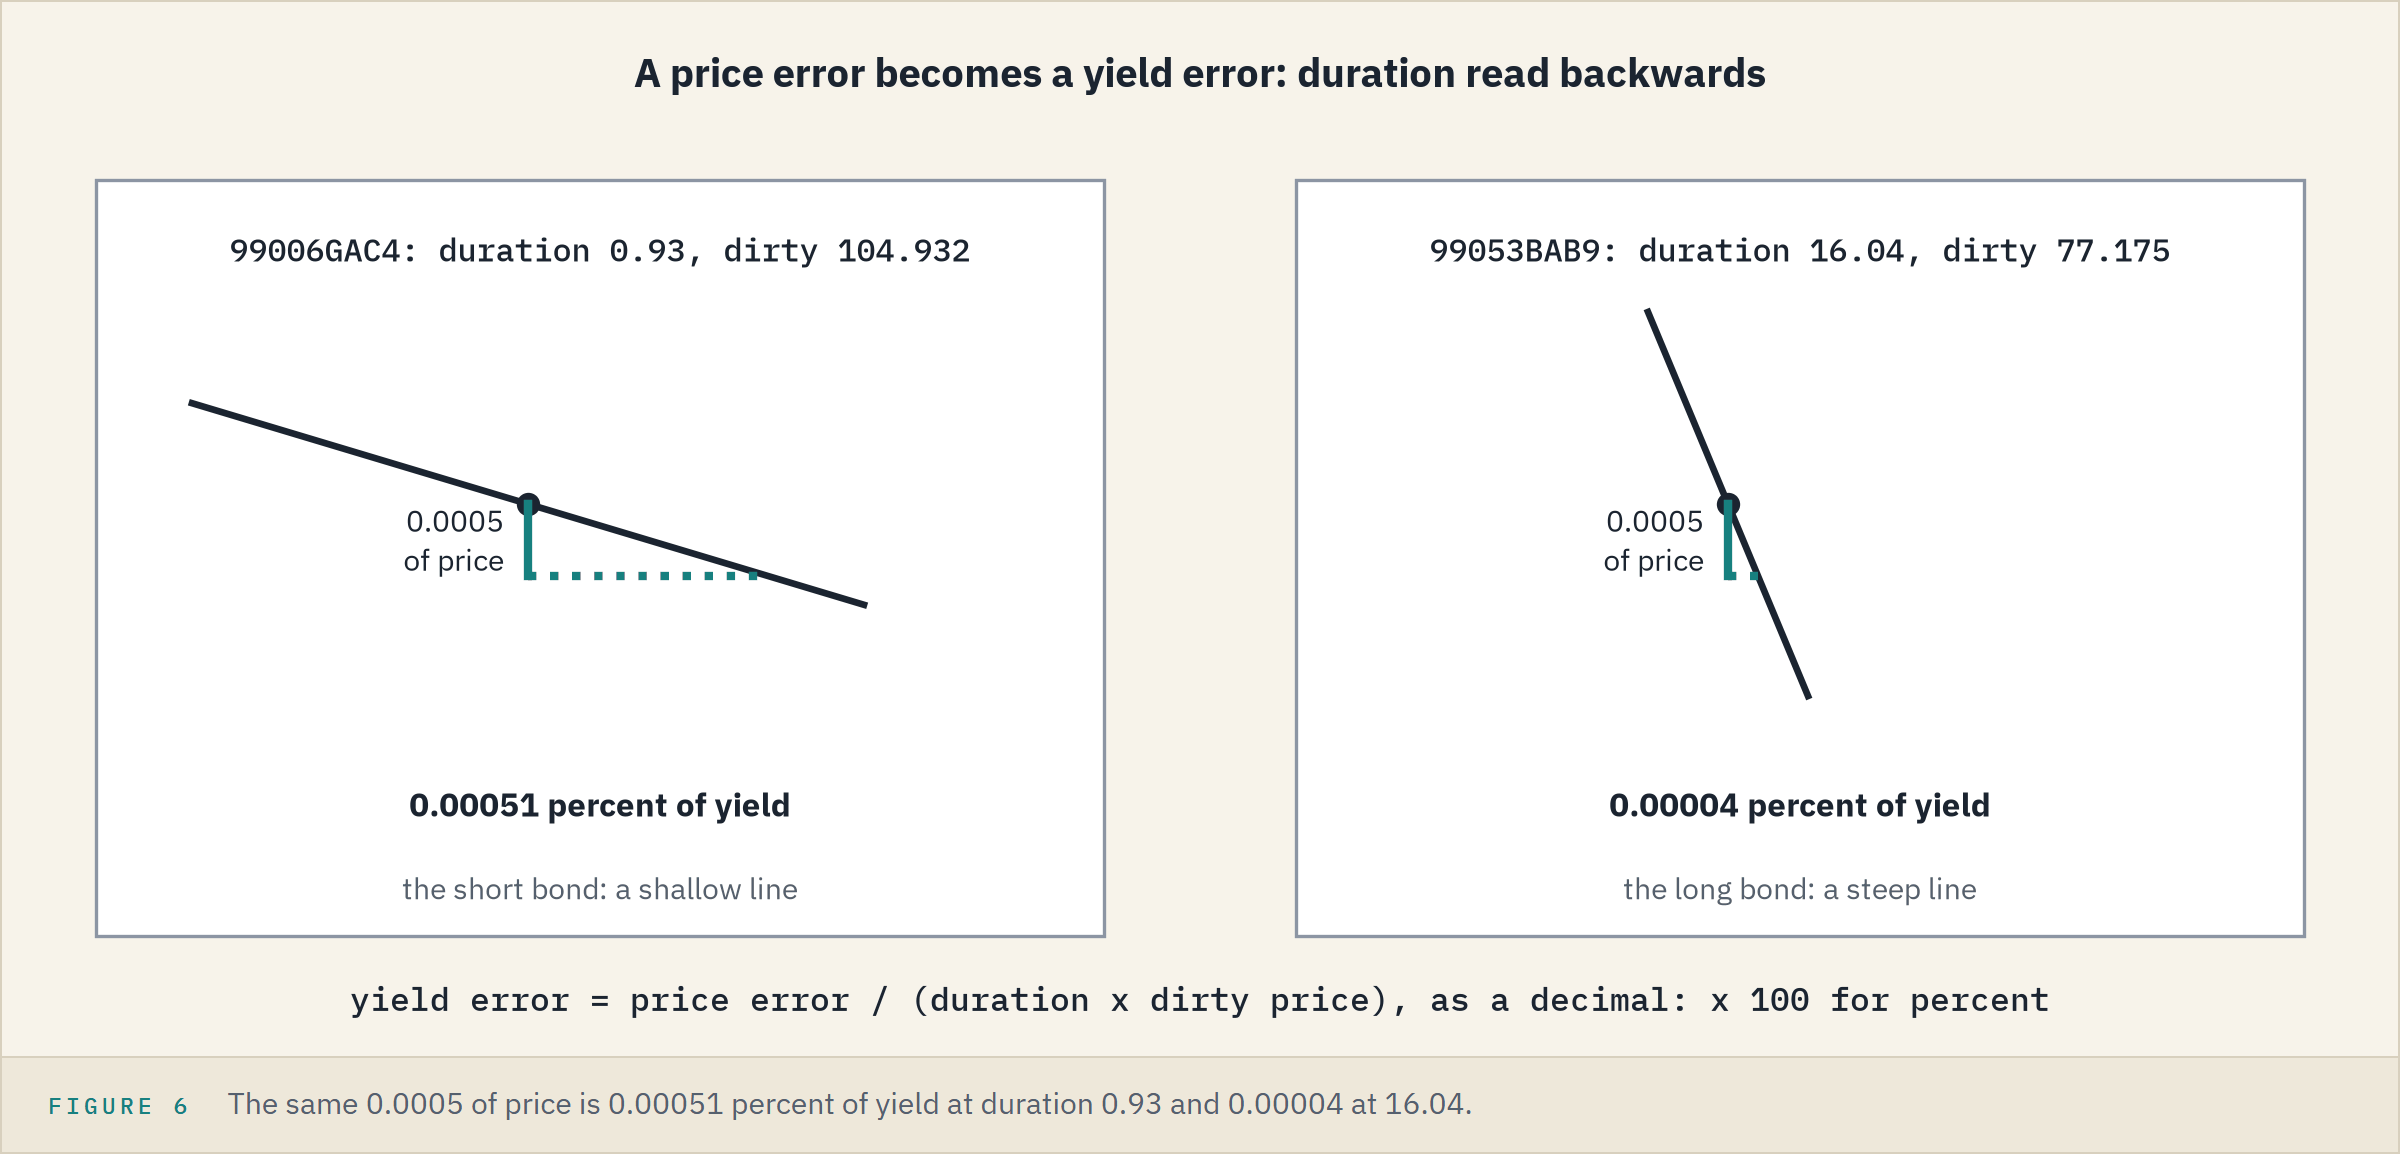

C: the five widest gaps all belong to bonds of 1.31 years' duration or less.
It is duration read backwards: a price error moves the yield by about price error / (duration x dirty price), as a decimal.

### Yield Gap Against Duration

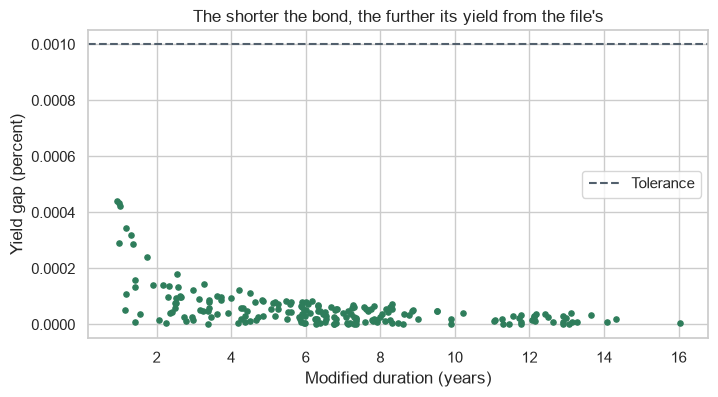

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(book['duration_calc'], book['yield_gap'], s=14)
ax.axhline(YIELD_FROM_ROUNDED_PRICE, linestyle='--', color='#52606D', label='Tolerance')
ax.set_title("The shorter the bond, the further its yield from the file's")
ax.set_xlabel('Modified duration (years)')
ax.set_ylabel('Yield gap (percent)')
ax.legend()
plt.show()

Bonds under 3 years average 0.000139 percent; bonds over 7 years, 0.000027.

**200 yields within 0.001 percent; the shortest bonds miss most, because duration turns a price error into a yield error.**

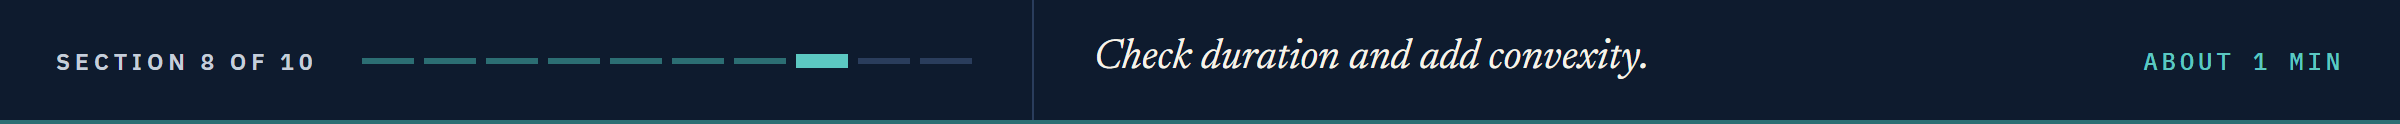

## 10.8 Duration, and Convexity as a New Column

### Duration Against the File, and a Column It Lacks

In [29]:
duration_gap = (book['duration_calc'] - book['duration']).abs()
assert duration_gap.max() <= ROUNDED_3
print(f'Largest duration gap {duration_gap.max():.7f} years')
book['convexity'] = [bondmath.convexity(*bond) for bond in inputs]
book[['duration_calc', 'convexity']].describe().round(4)

Largest duration gap 0.0004982 years


,duration_calc,convexity
count,200.0000,200.0000
mean,6.4704,72.5274
std,3.3505,76.3239
min,0.9271,1.3480
25%,3.8800,17.9547
50%,6.3062,50.0327
75%,8.1401,81.9089
max,16.0425,369.3686


The longest duration is 17 times the shortest; the largest convexity, 274 times the smallest.

### Against Excel's Central Difference

In [30]:
# the reference file's holdings rows: the same 200 bonds, by CUSIP
excel_fd = reference[reference['group'] == 'holdings'].set_index('case_id')['convexity_fd']
# two Series subtract label by label, CUSIP to CUSIP
convexity_gap = (book.set_index('cusip')['convexity'] - excel_fd).abs()
assert len(convexity_gap) == 200 and convexity_gap.max() < 1e-3
print(f'Largest gap {convexity_gap.max():.1e}, on {convexity_gap.idxmax()}')

Largest gap 2.2e-04, on 99053BAB9


**All four columns rebuilt, and a fifth added that Excel confirms: the note's third ask.**

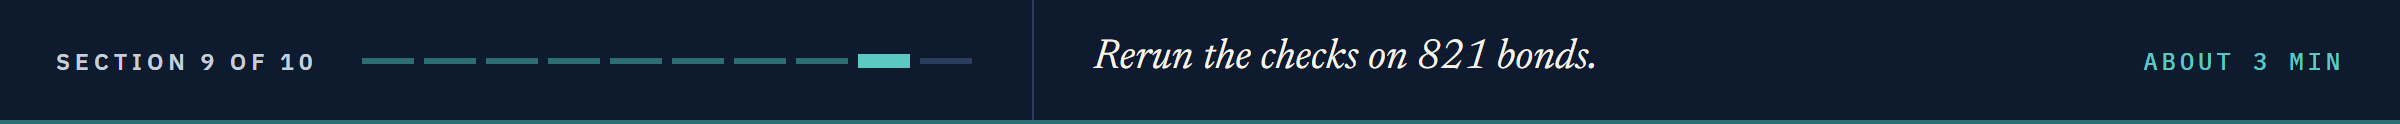

## 10.9 Two Systems Disagree, Again: the Benchmark

`benchmark.csv`, the wider file the holdings came from, has 821 bonds in the same columns.
Rather than copy four cells, put the checks in one function for any file of this shape.

**Rerun, do not redo.**

### One Function for Any File

In [31]:
def column_gaps(file):
    """The gaps between bondmath and the file in price, accrued, yield_pct and duration.

    file: a DataFrame with holdings.csv's columns. Gaps in the file's units, one row per CUSIP.
    """
    settle = pd.to_datetime(file['as_of_date']).dt.date
    maturity = pd.to_datetime(file['maturity']).dt.date
    terms = list(zip(settle, maturity, file['coupon'], file['yield_pct']))
    rebuilt = pd.DataFrame({
        'price': [bondmath.price(*bond) for bond in terms],
        'accrued': [bondmath.accrued_interest(s, m, c) for s, m, c, y in terms],
        'yield_pct': [bondmath.yield_to_maturity(s, m, c, p) for s, m, c, p
                      in zip(settle, maturity, file['coupon'], file['price'])],
        'duration': [bondmath.modified_duration(*bond) for bond in terms],
    }, index=file['cusip'])
    # rebuilt minus the file's own values, CUSIP by CUSIP and column by column
    return (rebuilt - file.set_index('cusip')[rebuilt.columns]).abs()

In [32]:
tolerance = pd.Series({'price': ROUNDED_3, 'accrued': ROUNDED_3,
                       'yield_pct': YIELD_FROM_ROUNDED_PRICE, 'duration': ROUNDED_3})
holdings_gaps = column_gaps(pd.read_csv('holdings.csv'))
# the Series lines up with the columns by name; .all().all(): every row of every column
assert (holdings_gaps <= tolerance).all().all()
print(len(holdings_gaps), 'holdings bonds, every gap inside its tolerance')

200 holdings bonds, every gap inside its tolerance


### 821 Bonds

In [33]:
benchmark = pd.read_csv('benchmark.csv')
benchmark_gaps = column_gaps(benchmark)
# .any(axis=1): True for a row where any one of its columns is True
outside = benchmark_gaps[(benchmark_gaps > tolerance).any(axis=1)]
print(len(benchmark_gaps), 'benchmark bonds,', len(outside), 'outside a tolerance')
outside.round(6)

821 benchmark bonds, 2 outside a tolerance


,price,accrued,yield_pct,duration
cusip,,,,
99018SAA8,0.000162,0.028917,0.000019,0.005182
99128YAE4,0.004826,0.052333,0.000762,0.005623


Two bonds: the February month-end pair from notebook 06's Two Systems Disagree.
Excel's month-end rule, which the module follows, puts their last coupon on 31 August; the data generator kept the 28th.
Different coupon dates, different days accrued: `accrued`, `duration` and one price differ.

### Left Out by Name

In [34]:
# named, not filtered by a rule: a third bond outside a tolerance must still stop the notebook
month_end_pair = ['99018SAA8', '99128YAE4']
assert sorted(outside.index) == month_end_pair
others = benchmark_gaps.drop(month_end_pair)
assert (others <= tolerance).all().all()
print(len(others), 'other benchmark bonds, every gap inside its tolerance')

819 other benchmark bonds, every gap inside its tolerance


Neither system is wrong: a real bond's documents decide.
Before comparing two systems, check which convention built each number.

**819 of 821 tie; the two that do not are notebook 06's February month-end bonds, a convention, not an error.**

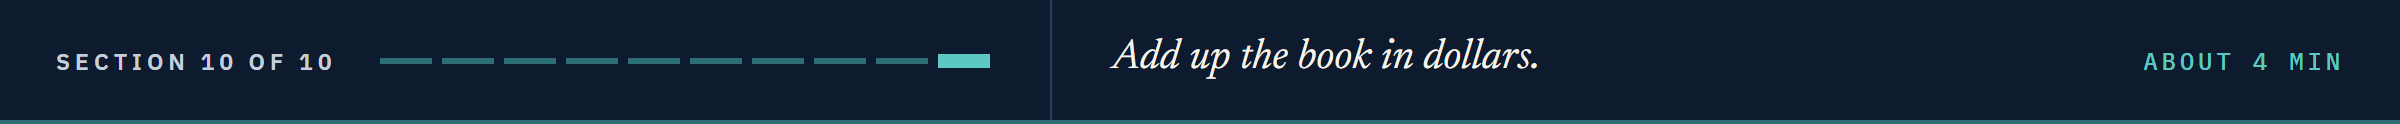

## 10.10 The Book in Dollars per Basis Point

Two totals describe the book's rate risk: **book DV01**, each position's dollars per bp added up (notebook 09), and the **market-value weighted duration**.
Market value uses the dirty price: par held x (price + accrued) / 100.

### Market Value, to the Cent

In [35]:
book['market_value_calc'] = book['par_held'] * (book['price'] + book['accrued']) / 100
total_market_value = book['market_value_calc'].sum()
# the control total: the file's own column, to the cent
assert abs(total_market_value - book['market_value'].sum()) < 0.005
print(f'Market value {total_market_value:,.2f} dollars')

Market value 490,819,215.00 dollars


### Book DV01 and Duration

In [36]:
# each position: DV01 per 100 x par held / 100, in dollars per bp
book['dv01_dollars'] = [bondmath.dv01(*bond) * par / 100
                        for bond, par in zip(inputs, book['par_held'])]
book_dv01_dollars = book['dv01_dollars'].sum()
weights = book['market_value_calc'] / total_market_value
book_duration = (weights * book['duration_calc']).sum()
print(f'Book DV01 {book_dv01_dollars:,.2f} dollars per bp, duration {book_duration:.4f} years')

Book DV01 306,996.11 dollars per bp, duration 6.2548 years


**Excel side by side.** The 200 bonds in a sheet, one to a row from row 2: settlement in A, maturity B, coupon C, yield D, par held E, the file's price F and accrued G.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">DV01 per 100, H2</td><td align="left"><code>bondmath.dv01(*bond)</code></td><td align="left"><code>=MDURATION(A2,B2,C2/100,D2/100,2,0)*(PRICE(A2,B2,C2/100,D2/100,100,2,0)+100*C2/100/2*COUPDAYBS(A2,B2,2,0)/COUPDAYS(A2,B2,2,0))/10000</code></td><td align="left">filled down</td></tr>
<tr><td align="left">Market value, I2</td><td align="left"><code>book['market_value_calc']</code></td><td align="left"><code>=E2*(F2+G2)/100</code></td><td align="left">filled down</td></tr>
<tr><td align="left">Modified duration, J2</td><td align="left"><code>book['duration_calc']</code></td><td align="left"><code>=MDURATION(A2,B2,C2/100,D2/100,2,0)</code></td><td align="left">filled down</td></tr>
<tr><td align="left">Book DV01</td><td align="left"><code>book_dv01_dollars</code></td><td align="left"><code>=SUMPRODUCT(E2:E201,H2:H201)/100</code></td><td align="left">306,996.11</td></tr>
<tr><td align="left">Market value</td><td align="left"><code>total_market_value</code></td><td align="left"><code>=SUM(I2:I201)</code></td><td align="left">490,819,215.00</td></tr>
<tr><td align="left">Book duration</td><td align="left"><code>book_duration</code></td><td align="left"><code>=SUMPRODUCT(I2:I201,J2:J201)/SUM(I2:I201)</code></td><td align="left">6.254772</td></tr>
</table>
<br clear="left">

### Predict 5: Two Routes to One Number

**Predict 5**

Q. Book duration x market value x 0.0001 is a second route to book DV01, using the file's rounded prices. Against the summed DV01 column, it is:

A) equal to the cent
B) under 1 dollar apart
C) over 100 dollars apart

### Both Routes

In [37]:
duration_route = book_duration * total_market_value * 0.0001
print(f'Duration route {duration_route:,.2f}, summed DV01 {book_dv01_dollars:,.2f} dollars')
print(f'Difference {book_dv01_dollars - duration_route:,.2f} dollars')

Duration route 306,996.21, summed DV01 306,996.11 dollars
Difference -0.10 dollars


B: 0.10 dollars apart, from the file's rounded prices.
Each position's DV01 is its duration x market value x 0.0001, so the sum is the book's: one number in two units.

### By Rating Group

In [38]:
# rstrip('+-') drops a + or - at the end, so A+ and A- both count as A
book['rating_group'] = book['rating'].str.rstrip('+-')
order = ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC']
by_rating = book.groupby('rating_group')[['market_value_calc', 'dv01_dollars']].sum()
by_rating = by_rating.reindex(order)
by_rating['dv01_per_million'] = by_rating['dv01_dollars'] / by_rating['market_value_calc'] * 1e6
by_rating.round(0)

,market_value_calc,dv01_dollars,dv01_per_million
rating_group,,,
AAA,8200605.0,4679.0,571.0
AA,13048305.0,5403.0,414.0
A,148505040.0,95015.0,640.0
BBB,151163415.0,109669.0,725.0
BB,113754240.0,63537.0,559.0
B,43595535.0,23096.0,530.0
CCC,12552075.0,5598.0,446.0


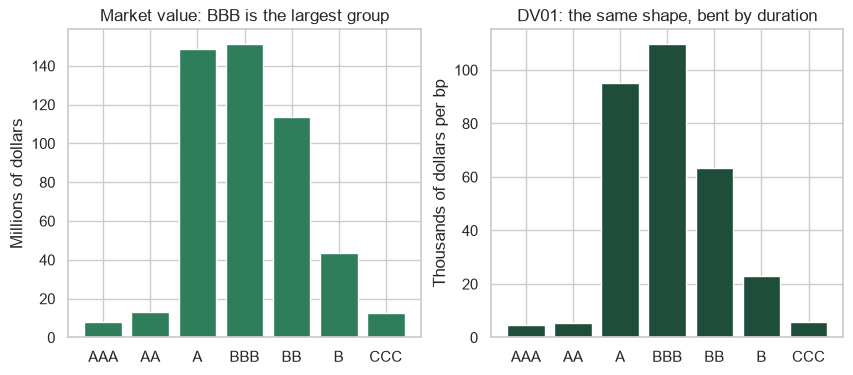

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(order, by_rating['market_value_calc'] / 1e6)
axes[0].set_title('Market value: BBB is the largest group')
axes[0].set_ylabel('Millions of dollars')
axes[1].bar(order, by_rating['dv01_dollars'] / 1e3, color='#1E4D3A')
axes[1].set_title('DV01: the same shape, bent by duration')
axes[1].set_ylabel('Thousands of dollars per bp')
plt.show()

AA carries 414 dollars of DV01 per million of market value and BBB 725: where duration differs, the shapes differ.
This describes the book; it judges no group.

**The book moves 306,996.11 dollars a basis point, duration 6.2548 years: the note is answered.**

## Summary

The checks behind every answer:

<table align="left">
<tr><th align="left">Check</th><th align="left">Result</th></tr>
<tr><td align="left"><code>convexity</code> against Excel's three <code>PRICE</code> cells</td><td align="left">294 rows within 1e-3, Halvering 4.8e-06</td></tr>
<tr><td align="left">pytest</td><td align="left">28 passed</td></tr>
<tr><td align="left">Price, accrued, duration against the file</td><td align="left">200 of 200 within 0.0005 + 1e-9</td></tr>
<tr><td align="left">Yield from the file's price</td><td align="left">200 of 200 within 0.001 percent, largest 0.000440</td></tr>
<tr><td align="left">Benchmark</td><td align="left">819 of 821, two named month-end bonds</td></tr>
<tr><td align="left">Market value</td><td align="left">490,819,215.00 dollars, to the cent</td></tr>
<tr><td align="left">Book DV01, two routes</td><td align="left">0.10 dollars apart</td></tr>
</table>
<br clear="left">

## Bring It Home

Copy the work folder's two files into your `my_bondmath` folder; the copy replaces yours, so anything of your own must be in the work folder first.
In PowerShell in VS Code, with the course's `.venv` active and the folder name the setup printed:

```powershell
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$env:TEMP\pfi_course2_10_k4w7q2xr\bondmath.py", "$env:TEMP\pfi_course2_10_k4w7q2xr\test_bondmath.py" .
python -m pytest -q
git diff --stat
git commit -am "Add convexity, checked against a central difference on Excel PRICE"
git tag week2
git diff --stat week1 week2
```

pytest shows 28 passed, more with your exercise tests.
In Colab, download the two files from the work folder under `/tmp`.
The work folder stays in your temp folder until the system clears it.

## You Can Now

By the end of this notebook, you can:

* Say where duration's line misses a full reprice, and why the miss grows with the square of the move.
* Compute convexity with `bondmath.convexity` and say how other sources scale it.
* Check convexity against three `PRICE` cells, since Excel has no convexity function.
* Estimate a price change with duration and convexity.
* Rebuild a file's four columns at stated tolerances, and leave out a known exception by name.
* Add up a book's DV01 in dollars and its weighted duration, and say why they are one number.
* Compare two tags with `git diff --stat` and `git log`.

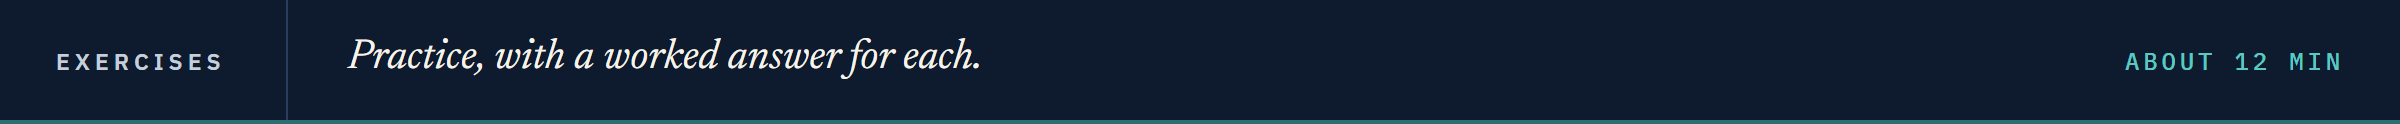

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The second set of four bonds, settled 30 November at their issue yields.
Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: `check`, and the bonds.

In [40]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [41]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'maturity': [date(2030, 9, 30), date(2028, 9, 30), date(2032, 9, 30), date(2034, 9, 30)],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})
exercise_bonds

,ticker,coupon_pct,maturity,yield_pct
0,OSTV,5.625,2030-09-30,5.80
1,TRNW,4.375,2028-09-30,4.30
2,OSMC,5.000,2032-09-30,5.35
3,CLDB,8.250,2034-09-30,8.60


### Exercise 1

Q. Compute the convexity of the four bonds. Store Calderby's (`CLDB`) in **ex1_calderby**, and the ticker with the largest convexity in **ex1_largest**.

In [42]:
ex1_calderby = ...
ex1_largest = ...

In [43]:
check('Exercise 1 Calderby convexity', ex1_calderby, 40.151840380885986)
check('Exercise 1 largest convexity', ex1_largest, 'CLDB')

Exercise 1 Calderby convexity: not attempted yet
Exercise 1 largest convexity: not attempted yet


### Exercise 2

Q. Osmere's (`OSMC`) yield rises 200 bp. Store the duration-and-convexity estimate of its dirty price's change, in percent, in **ex2_estimate_pct**, and the full reprice's change, in percent, in **ex2_full_pct**.

In [44]:
ex2_estimate_pct = ...
ex2_full_pct = ...

In [45]:
check('Exercise 2 estimate', ex2_estimate_pct, -9.316371448913852)
check('Exercise 2 full reprice', ex2_full_pct, -9.340810588211228)

Exercise 2 estimate: not attempted yet
Exercise 2 full reprice: not attempted yet


### Exercise 3

Q. Add `convexity_adjustment(convexity, shift_bp)`, docstring first (units, convention, the unscaled convexity it expects): the percent change from convexity alone, 0.5 x convexity x dy ** 2 x 100. Test it with `test_convexity_adjustment_hand_cases`: convexity 100 and 100 bp give 0.5, -100 bp the same, 0 bp gives 0. Run pytest, reload, and store Calderby's adjustment for 100 bp in **ex3_calderby**.

In [46]:
%%writefile -a bondmath.py


# Exercise 3: write convexity_adjustment(convexity, shift_bp) below this line

Appending to bondmath.py


In [47]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_convexity_adjustment_hand_cases() below this line

Appending to test_bondmath.py


In [48]:
# run pytest as in the lesson, reload the module, then call your function
ex3_calderby = ...

In [49]:
check('Exercise 3 Calderby adjustment', ex3_calderby, 0.20075920190442995)

Exercise 3 Calderby adjustment: not attempted yet


### Exercise 4: AI check

You gave an assistant the docstring of `convexity` (10.2) as the prompt.
The function below came back, written for this course in the style of an assistant's answer; it runs, and holds one bug.

In [50]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def assistant_convexity(settlement, maturity, coupon_pct, yield_pct, frequency=2,
                        basis='30/360'):
    """Convexity in years squared, unscaled (not divided by 100 or by 2)."""
    dates = bondmath.coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = bondmath.coupon_period_days(settlement, maturity,
                                                                  frequency, basis)
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(len(dates) - 1):
        cash_flow = coupon_pct / frequency + (100 if k == len(dates) - 2 else 0)
        # time to each cash flow, counted in coupon periods
        periods = w + k
        total_pv += cash_flow / (1 + period_yield) ** periods
        curvature += cash_flow * periods * (periods + 1) / (1 + period_yield) ** (periods + 2)
    return curvature / total_pv

Q. Section 10.2 has Halvering's convexity. What does the assistant's function give?

In [51]:
print(f'{assistant_convexity(settlement, date(2036, 9, 30), 7.5, 7.7):.4f}')

238.1895


Q. Test it on every reference row outside the final period before you trust it.

In [52]:
# the test file's reference rows and bond_inputs, read as today's test reads them
from test_bondmath import REFERENCE, bond_inputs
rows = [row for row in REFERENCE if row['coupnum'] != '1']
for row in rows:
    result = assistant_convexity(*bond_inputs(row))
    excel_value = float(row['convexity_fd'])
    message = f"{row['case_id']}: {result:.4f}, Excel {excel_value:.4f}"
    assert abs(result - excel_value) < 1e-3, message
print('Every row matches convexity_fd')

AssertionError: 99080CAE8: 105.4320, Excel 26.3580

Q. Read the message, find the convention the code broke, and fix the function until the test passes. Store the fixed function's convexity for Halvering in **ex4_halvering**.

In [53]:
ex4_halvering = ...

In [54]:
check('Exercise 4 Halvering convexity', ex4_halvering, 59.54736368900526)

Exercise 4 Halvering convexity: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">The line's miss at 100 bp</td><td align="left">Halvering 0.2879 per 100 up, 0.3073 down</td></tr>
<tr><td align="left">The bend in <code>bondmath</code></td><td align="left"><code>convexity</code>, Halvering 59.5474 years squared, Excel's cells within 4.8e-06</td></tr>
<tr><td align="left">The file's four columns</td><td align="left">200 of 200 bonds within rounding</td></tr>
<tr><td align="left">The benchmark</td><td align="left">819 of 821, two February month-end bonds by convention</td></tr>
<tr><td align="left">The book</td><td align="left">306,996.11 dollars per bp, duration 6.2548 years</td></tr>
</table>
<br clear="left">

Be proud: you rebuilt someone else's book from your own module and can say where every number comes from.

Next: Treasury Curve Interpolation (notebook 11) splits each yield into a curve and a spread.

[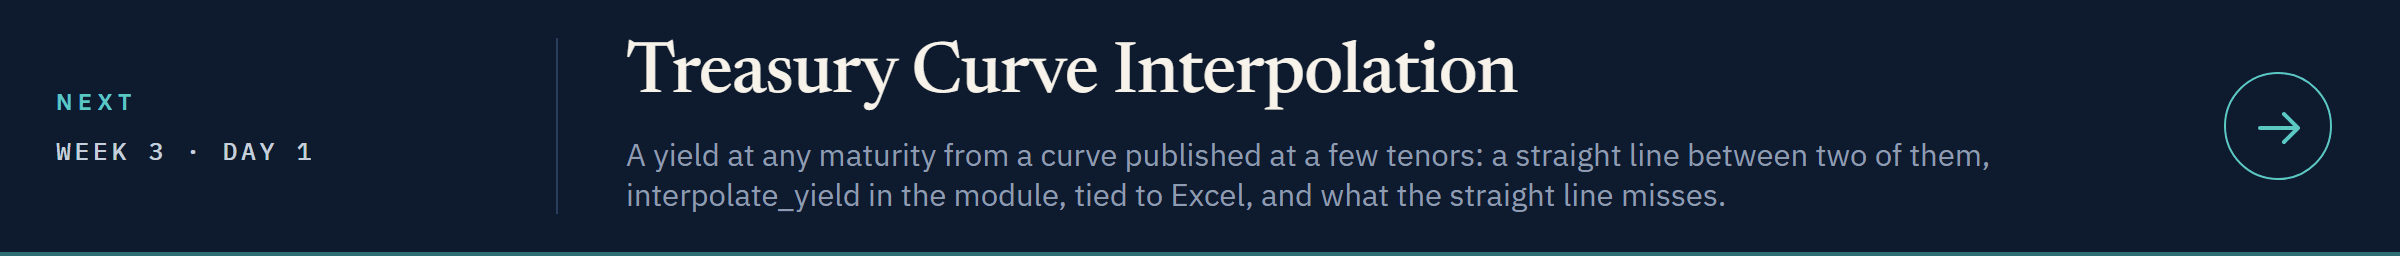](../../week3/day1/11_treasury_curve_interpolation.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day1/11_treasury_curve_interpolation.ipynb)